# 02 Fenster und Features – interaktive Exploration

**Frage:** Welcher Versuch gehört zu welchem Maschinenzustand (**Basis, Zustand 1, Zustand 2**)? Bekannt ist nur: **V01 war im Basiszustand** (vermutlich auch V02, unsicher). Weitere Labels gibt es nicht. Außerdem wissen wir: Die Zustände kamen **nacheinander** (z. B. V01–V03 Basis, V04–V08 Zustand 1, V09–V10 Zustand 2), nie durcheinander. Gesucht sind also **die zwei Stellen, an denen sich der Zustand geändert hat**. Dafür suchen wir zuerst **Fenster und Features, die die Versuche klar trennen, aber innerhalb eines Versuchs stabil sind**, und prüfen dann alle möglichen Einteilungen in aufeinanderfolgende Blöcke.

Ablauf (Schritte 02–04 aus Session 2):

1. **Fenster bilden** aus den bereinigten Daten (`clean/`, aus `01_Bereinigung.ipynb`). Die Zeitbereiche wählt man selbst anhand der Graphen (Beschleunigung und Magnetfeld). Darin werden Fenster fester Länge mit Überlappung geschnitten.
2. **Features berechnen** mit **tsfresh** (Beschleunigung, Gyroskop und Magnetfeld, je x, y, z und Betrag), dazu optional die Energie in den Frequenzbändern 45,5 / 86 / 121,6 Hz.
3. **Featurematrix bereinigen:** Spalten mit vielen Fehlwerten oder ohne Streuung entfernen, restliche Lücken mit dem Median füllen.
4. **Features bewerten** (Ranking), die besten darstellen und die **beste Einteilung in aufeinanderfolgende Zustände** suchen.

**Bedienung:** Abschnitt 5 (Steuerung) ausführen. Versuche wählen → Graphen ansehen → Bereich und Fenster einstellen (wird live in allen Graphen angezeigt) → **Berechnen**. Jeder Lauf wird in `runs_log.csv` protokolliert. Abschnitt 6 enthält fest ausgeführte Beispielläufe, die auch ohne Widgets sichtbar sind.

In [1]:
import io, os, time, warnings
from itertools import combinations
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, periodogram
from scipy.stats import f_oneway
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import calinski_harabasz_score
from tsfresh import extract_features
from tsfresh.feature_extraction import MinimalFCParameters, EfficientFCParameters
import ipywidgets as W
from IPython.display import display
warnings.filterwarnings('ignore')   # tsfresh/numpy warn about NaN features – those are handled in step 3

CLEAN = Path('clean')              # output of 01_Bereinigung.ipynb
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
LOG = Path('runs_log.csv')         # one line per run, to compare settings later
MATRIX_DIR = Path('features'); MATRIX_DIR.mkdir(exist_ok=True)   # one feature matrix file per run
N_JOBS = os.cpu_count()            # tsfresh runs in parallel on all cores
BANDS = [45.5, 86.0, 121.6]        # drive lines found in the EDA (Hz)
MIN_B_RANGE = 5.0                  # µT – recordings with a flatter |B| curve are not aligned

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'font.size': 9, 'legend.frameon': False})
pd.set_option('display.width', 250, 'display.max_columns', 30, 'display.max_colwidth', 80)

# Cleaned data, split by recording for fast access
REC = pd.read_csv(CLEAN / 'aufnahmen.csv', dtype={'Versuch': str}).set_index('record_id')
REC['Versuch'] = 'V' + REC['Versuch']
DATA = {s: dict(tuple(pd.read_csv(CLEAN / f'{s}.csv').groupby('record_id'))) for s in ['acc', 'gyro', 'mag']}
FS = {(r, s): 1 / np.median(np.diff(DATA[s][r]['t'].values)) for s in DATA for r in DATA[s]}   # sampling rate
print(len(REC), 'Messungen geladen:', ', '.join(REC.index))

33 Messungen geladen: V01_FP_01, V02_FP_01, V02_IP_01, V03_FP_01, V03_FP_02, V03_FP_03, V03_IP_01, V03_IP_02, V03_IP_03, V04_FP_01, V04_FP_02, V04_IP_01, V04_IP_02, V04_IP_03, V05_FP_01, V05_FP_02, V05_FP_03, V05_IP_01, V05_IP_02, V05_IP_03, V06_FP_01, V06_FP_02, V06_FP_03, V07_FP_01, V08_FP_01, V08_IP_01, V09_FP_01, V09_FP_02, V09_FP_03, V10_FP_01, V10_FP_02, V10_FP_03, V10_IP_03


## 1 · Fenster bilden

- **Ausrichten nach Magnetfeld** (optional): Die Fahrten beginnen in jeder Messung unterschiedlich spät. Das Magnetfeld |B| zeigt, wo der Schlitten ist. Jede Messung wird so verschoben, dass ihr |B|-Verlauf am besten zu einer Referenzmessung passt (Kreuzkorrelation der normierten Kurven, maximal ±30 s; Referenz = die gewählte Messung mit der größten |B|-Spanne). Danach trifft ein gemeinsamer Bereich in allen Messungen **dieselbe Phase** (z. B. die Rückfahrt). Das entspricht der Idee von DTW aus der Vorlesung: gleiche Form, zeitlich versetzt. Messungen mit fast konstantem |B| (Spanne unter 5 µT, ortsfestes Handy) werden nicht verschoben.
- **Bereiche** (von–bis in Sekunden, bei Ausrichtung in der Zeit der Referenz) wählt man selbst anhand der Graphen. Dieselben Bereiche gelten für alle gewählten Messungen. Ohne Bereich wird die ganze Messung verwendet.
- **Fenster:** In jedem Bereich werden Fenster der Länge *L* mit Überlappung (0–75 %) geschnitten.
- Ein Fenster wird nur verwendet, wenn es **vollständig in einem Segment** liegt (keine Aufnahmepause dazwischen), **alle Werte gültig** sind (siehe `01_Bereinigung.ipynb`) und jeder Sensor mindestens 90 % der erwarteten Werte liefert. Reicht ein Bereich über das Ende einer Messung hinaus, entstehen dort einfach keine Fenster.
- **Beide Geräte zusammen:** Fairphone-Beschleunigung und -Gyroskop (427 Hz) werden auf 100 Hz heruntergerechnet (Tiefpass 45 Hz, dann Interpolation), damit die Features beider Handys dasselbe bedeuten. Bänder über 50 Hz entfallen dann.

In [2]:
def recordings(cfg):
    # Recordings of the selected Versuche and device, in a fixed order
    return [r for r in REC.index if REC.loc[r, 'Versuch'] in cfg['versuche']
            and (cfg['geraet'] == 'beide' or REC.loc[r, 'Gerät'] == cfg['geraet'])]


def b_curve(rid):
    # |B| of one recording on its own time axis
    m = DATA['mag'][rid]
    return m['t'].values, np.linalg.norm(m[['x', 'y', 'z']].values, axis=1)


ALIGN_CACHE = {}

def alignment(cfg):
    # Shift (s) per recording so that its |B| curve matches the reference best; 0 if not aligned
    rids = recordings(cfg)
    if not cfg.get('ausrichten') or not rids:
        return {r: 0.0 for r in rids}, None
    key = tuple(rids)
    if key not in ALIGN_CACHE:
        span = {r: np.ptp(b_curve(r)[1]) for r in rids}
        ref = max(span, key=span.get)
        def norm(r):
            t, b = b_curve(r)
            grid = np.arange(0, t.max(), 0.05)                       # common 20 Hz grid
            x = np.interp(grid, t, pd.Series(b).rolling(50, center=True, min_periods=1).median().values)
            return (x - x.mean()) / (x.std() + 1e-9)
        xr = norm(ref)
        shifts = {}
        for r in rids:
            if span[r] < MIN_B_RANGE or r == ref:
                shifts[r] = 0.0; continue
            x = norm(r)
            c = np.correlate(x, xr, mode='full')                     # lag > 0: recording runs later than the reference
            lags = (np.arange(len(c)) - (len(xr) - 1)) * 0.05
            ok = np.abs(lags) <= 30
            # normalise by the overlap length, so large shifts are not favoured or penalised by the edges
            overlap = len(xr) - np.abs(np.arange(len(c)) - (len(xr) - 1))
            shifts[r] = float(lags[ok][np.argmax((c / np.maximum(overlap, 1))[ok])])
        ALIGN_CACHE[key] = (shifts, ref)
    return ALIGN_CACHE[key]


def window_spans(rid, cfg, shift=0.0):
    # Start/end of all windows of one recording inside the chosen ranges, plus how many were rejected.
    # Ranges are given in aligned time; shift converts them to the recording's own time.
    L = cfg['laenge']
    step = L * (1 - cfg['ueberlappung'] / 100)
    ranges = [(a + shift, b + shift) for a, b in cfg['bereiche']] or [(0, np.inf)]
    spans, rejected = [], 0
    for seg, d in DATA['acc'][rid].groupby('segment'):
        t0, t1 = d['t'].min(), d['t'].max()
        for a, b in ranges:
            lo, hi = max(a, t0), min(b, t1)
            for s in np.arange(lo, hi - L + 1e-9, step):
                ok = True
                for sensor in cfg['sensoren']:
                    x = DATA[sensor][rid]
                    i0, i1 = np.searchsorted(x['t'].values, [s, s + L])
                    w = x.iloc[i0:i1]
                    if len(w) < 0.9 * FS[rid, sensor] * L or not w['gueltig'].all() or (w['segment'] != seg).any():
                        ok = False; break
                if ok:
                    spans.append((seg, s, s + L))
                else:
                    rejected += 1
    return spans, rejected


def resample(df, fs):
    # Low-pass (below the new Nyquist frequency) and interpolate onto a regular grid, per segment
    out = []
    for seg, d in df.groupby('segment'):
        t = d['t'].values
        fs_old = 1 / np.median(np.diff(t))
        grid = np.arange(t[0], t[-1], 1 / fs)
        cols = {'t': grid, 'segment': seg}
        for c in 'xyz':
            x = d[c].values
            if fs_old > fs * 1.05 and len(x) > 30:
                x = sosfiltfilt(butter(4, 0.45 * fs, 'lp', fs=fs_old, output='sos'), x)
            cols[c] = np.interp(grid, t, x)
        out.append(pd.DataFrame(cols))
    return pd.concat(out, ignore_index=True)


def make_windows(cfg):
    # Window table (metadata) and the window data in tsfresh long format
    meta, long, rejected = [], [], 0
    shifts, _ = alignment(cfg)
    for rid in recordings(cfg):
        spans, rej = window_spans(rid, cfg, shifts[rid])
        rejected += rej
        sig = {s: (resample(DATA[s][rid], 100.0) if cfg['geraet'] == 'beide' and s in ('acc', 'gyro') else DATA[s][rid])
               for s in cfg['sensoren']}
        for seg, a, b in spans:
            wid = f'{rid}_{a:07.2f}'
            meta.append({'id': wid, 'record_id': rid, 'Versuch': REC.loc[rid, 'Versuch'], 'Gerät': REC.loc[rid, 'Gerät'],
                         'segment': seg, 'start': round(a, 3), 'ende': round(b, 3), 'verschiebung': shifts[rid]})
            for s, d in sig.items():
                w = d[(d['segment'] == seg) & (d['t'] >= a) & (d['t'] < b)]
                xyz = w[['x', 'y', 'z']].values
                chans = {f'{s}_betrag': np.linalg.norm(xyz, axis=1)}
                if not cfg['nur_betrag']:        # axes depend on how the phone lies, the magnitude does not
                    chans.update({f'{s}_x': xyz[:, 0], f'{s}_y': xyz[:, 1], f'{s}_z': xyz[:, 2]})
                for k, v in chans.items():
                    if cfg['lage_ausschliessen']:
                        v = v - v.mean()         # remove the window mean: orientation (gravity) and position (|B| level)
                    long.append(pd.DataFrame({'id': wid, 'time': np.arange(len(v)), 'kind': k, 'value': v, '_t': w['t'].values}))
    long = pd.concat(long, ignore_index=True) if long else pd.DataFrame(columns=['id', 'time', 'kind', 'value', '_t'])
    return pd.DataFrame(meta), long, rejected

## 2 · Features berechnen

- **Sensoren:** **Beschleunigung** (Vibration, Rucke), **Gyroskop** (Drehrate: Kippeln und Wackeln, z. B. durch lose Schrauben oder Rollen, das in der Beschleunigung kaum auffällt) und **Magnetfeld** (Lage des Schlittens). Die übrigen Dateien der Handys (lineare Beschleunigung, beim iPhone Luftdruck, GPS, Näherungssensor) enthalten nichts Neues bzw. nichts über die Maschine, siehe `01_Bereinigung.ipynb`.
- **tsfresh** berechnet für jedes Fenster und jeden Kanal (acc_x, acc_y, acc_z, acc_betrag, gyro_x, …, mag_betrag) viele Kennzahlen. *Klein* = `MinimalFCParameters` (10 pro Kanal: Mittelwert, Streuung, Maximum, …). *Groß* = `EfficientFCParameters` (≈ 780 pro Kanal, u. a. Autokorrelation, FFT-Koeffizienten, Entropie).
- **Lageunabhängig** (Standard): Von jedem Kanal wird der Fenster-Mittelwert abgezogen, bevor tsfresh rechnet. Sonst würden die Features vor allem zeigen, wie das Handy geneigt ist (Schwerkraft auf x/y/z), wo es liegt (|B|-Niveau) und welchen Nullpunktfehler sein Gyroskop hat, nicht wie die Maschine läuft. Features, die dadurch nur noch Rechenrauschen enthalten (Mittelwert, Summe) oder durch den Mittelwert ≈ 0 teilen (Variationskoeffizient), werden entfernt. Ebenso der FFT-Koeffizient 0 (= Fenstersumme ≈ 0): Sein Rundungsrauschen hängt vom abgezogenen Niveau ab und würde die Lage durch die Hintertür wieder einführen.
- **Nur Betrag:** Auch nach dem Mittelwert-Abzug hängt es von der Ausrichtung des Handys ab, *welche* Achse die Vibration aufnimmt. Mit dieser Option werden nur |a| und |B| verwendet, die von der Ausrichtung unabhängig sind.
- **Frequenzbänder** (eigene Features, nicht tsfresh): Leistung der Beschleunigung in ±1,5 Hz um 45,5 / 86 / 121,6 Hz, summiert über x, y, z (bzw. aus |a| bei „nur Betrag“), damit unabhängig von der Lage, als log₁₀. Nur Bänder unterhalb der halben Abtastrate.

In [3]:
def band_features(long):
    # Power of the acceleration in narrow bands around the drive lines, summed over x, y, z
    rows = {}
    kinds = ['acc_x', 'acc_y', 'acc_z'] if 'acc_x' in set(long['kind']) else ['acc_betrag']   # magnitude only: use |a|
    acc = long[long['kind'].isin(kinds)]
    for wid, g in acc.groupby('id', sort=False):
        t = g.loc[g['kind'] == kinds[0], '_t'].values
        fs = 1 / np.median(np.diff(t))
        psd = 0
        for k in kinds:
            f, p = periodogram(g.loc[g['kind'] == k, 'value'].values, fs=fs, detrend='constant')
            psd = psd + p
        df = f[1] - f[0]
        rows[wid] = {f'band_{fb}Hz': np.log10(psd[np.abs(f - fb) <= max(1.5, df / 2)].sum() * df + 1e-12)
                     for fb in BANDS if fb + 1.5 < fs / 2}
    return pd.DataFrame.from_dict(rows, orient='index')


def freeze(v):
    # Lists (of ranges) -> tuples, so a setting can be used as a cache key
    return tuple(freeze(x) for x in v) if isinstance(v, (list, tuple)) else v

CACHE = {}

def features(cfg):
    # Window table + feature matrix X (rows = windows). Cached per setting (Top-N doesn't matter here).
    key = tuple((k, freeze(v)) for k, v in sorted(cfg.items()) if k != 'top')
    if key in CACHE:
        return CACHE[key]
    t0 = time.time()
    meta, long, rejected = make_windows(cfg)
    if meta.empty:
        raise ValueError('Keine gültigen Fenster – Bereich, Fensterlänge, Versuche oder Gerät ändern.')
    params = MinimalFCParameters() if cfg['merkmale'] == 'minimal' else EfficientFCParameters()
    X = extract_features(long[['id', 'time', 'kind', 'value']], column_id='id', column_sort='time', column_kind='kind',
                         column_value='value', default_fc_parameters=params, n_jobs=N_JOBS, disable_progressbar=True)
    if cfg['baender'] and 'acc' in cfg['sensoren']:
        X = X.join(band_features(long))
    X = X.loc[meta['id']]
    CACHE[key] = (meta, X, rejected, time.time() - t0)
    return CACHE[key]

## 3 · Featurematrix bereinigen

Regeln (wie in der Vorlesung: Fehlwerte und konstante Spalten behandeln, Entscheidungen protokollieren):

1. Spalten mit **mehr als 5 % Fehlwerten** (NaN/∞) entfernen.
2. Spalten **ohne Streuung** entfernen (Standardabweichung 0 oder nur Rechenrauschen nach dem Mittelwert-Abzug).
3. **Quasi-konstante** Spalten entfernen: derselbe Wert in mehr als der Hälfte aller Fenster. Das betrifft vor allem Gyroskop-Features: Das Fairphone-Gyroskop misst in Stufen von 0,00015 rad/s, die Drehungen der Achse sind nur wenige Stufen groß (28–62 verschiedene Werte pro Messung). Manche Features messen dann nur dieses Stufenrauschen, z. B. ein Median von 0,0 in jeder Messung mit trotzdem riesigem F.
4. Verbleibende einzelne Lücken mit dem **Median der Spalte** füllen.

Hinweis: Hier werden noch keine Modelle trainiert und getestet. Diese Bereinigung ist explorativ und auf alle gewählten Fenster angepasst. Für Training und Test (Session 3) muss sie nur auf den Trainingsdaten gelernt werden.

In [4]:
def clean_matrix(X, cfg):
    report = {'Features roh': X.shape[1]}
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.loc[:, X.isna().mean() <= 0.05]
    report['nach NaN-Regel'] = X.shape[1]
    if cfg['lage_ausschliessen']:
        # after subtracting the window mean these are only rounding noise (mean, sum, FFT coefficient 0)
        # or divide by ~0 (variation coefficient)
        X = X.loc[:, [c for c in X.columns if not (c.endswith('__mean') or c.endswith('__sum_values')
                                                   or '__variation_coefficient' in c or '__coeff_0' in c and 'fft_coefficient' in c)]]
    std = X.std()
    X = X.loc[:, (std > 1e-9 * (X.abs().max() + 1e-12)) & (std > 0)]
    report['nach Streuungs-Regel'] = X.shape[1]
    # quasi-constant: the same value in more than half of the windows (e.g. features stuck at the
    # resolution of the Fairphone gyroscope, which reports in steps of 0.00015 rad/s)
    mode_share = X.apply(lambda c: c.value_counts(normalize=True, dropna=True).iloc[0])
    X = X.loc[:, mode_share <= 0.5]
    report['nach Quasi-konstant-Regel'] = X.shape[1]
    X = X.fillna(X.median())
    return X, report

## 4 · Features bewerten, darstellen, Zustandswechsel suchen

**Featurematrix:** Jede Berechnung gibt die Sample-Feature-Matrix aus und speichert sie in `features/` (komprimiertes CSV, Dateiname aus Zeit und Einstellungen; der Pfad steht auch in `runs_log.csv`). Aufbau:

| Spalten | Bedeutung |
|---|---|
| `id` | Fenster-ID = Messung + Startzeit, z. B. `V09_FP_02_0031.00` |
| `record_id`, `Versuch`, `Gerät`, `segment`, `start`, `ende` | woher das Fenster stammt (IDs, **keine** Features) |
| `zustand_bekannt` | Zielwert, soweit bekannt: „Basis“ für V01, sonst leer (unbekannt) |
| alle weiteren | Features nach der Bereinigung (Abschnitt 3), Name = `sensor_kanal__berechnung__parameter`, z. B. `acc_betrag__number_peaks__n_1`, `band_86.0Hz` |

Eine Zeile = ein Fenster. Die Werte sind noch **nicht skaliert**: Skalierung und Auswahl gehören zur späteren Modellierung und werden dort nur auf den Trainingsdaten angepasst.

**Ranking (Trennschärfe F):** Für jedes Feature wird pro **Messung** der Median über ihre Fenster gebildet. Dann vergleicht ein F-Test (einfaktorielle ANOVA) die Streuung **zwischen den Versuchen** mit der Streuung **zwischen den Wiederholungen innerhalb eines Versuchs**. Ein hohes F bedeutet: Das Feature unterscheidet die Versuche, ist aber innerhalb eines Versuchs stabil. Man rechnet auf Messungen und nicht auf Fenstern, weil benachbarte Fenster einer Messung fast gleich sind. Sonst wäre fast jedes Feature „signifikant“. Bei tausenden Features ist F nur eine Rangfolge, kein Signifikanztest. Für das Ranking braucht es mindestens einen Versuch mit zwei Messungen.

**Top-N je Sensor, ohne Dubletten:** Von **jedem** gewählten Sensor werden die *N* besten Features genommen (bei drei Sensoren und N = 3 also 9). Sonst verdrängt ein Sensor die anderen nur wegen seiner Skala: Das Gyroskop erreicht F-Werte über 100 000, die Beschleunigung einige Hundert. Viele Features messen fast dasselbe. Ein Feature kommt nur in die Liste, wenn es mit keinem besseren eine Korrelation über 0,95 hat.

**Zustandsfolge statt freier Cluster:** Weil die Zustände nacheinander kamen, werden die gewählten Versuche in ihrer Reihenfolge in **2 oder 3 aufeinanderfolgende Blöcke** geteilt, und zwar auf **alle möglichen Arten** (bei V06, V08, V09, V10 z. B. „V06 | V08, V09, V10“, „V06 | V08, V09 | V10“, …). Für jede Einteilung wird gemessen, wie gut die Blöcke getrennt sind: **Calinski-Harabasz-Index (CH)** = Streuung zwischen den Blöcken ÷ Streuung innerhalb der Blöcke, jeweils geteilt durch die Zahl der Freiheitsgrade, damit 2 und 3 Blöcke fair vergleichbar sind. Gerechnet wird auf **allen Fenstern** mit den Top-Features (robust skaliert: Median und Quartilsabstand, auf ±5 begrenzt). Höheres CH = klarere Einteilung. Jede Einteilung ist erlaubt, auch ein Zustand aus nur einem Versuch. Weil auf Fenstern gerechnet wird, hat auch ein Versuch mit nur einer Messung (V01, V02, V08 mit dem Fairphone) eine echte Streuung in seinem Block und wird nicht künstlich bevorzugt. Jeder Block muss **mindestens 2 Messungen** enthalten: Ein Block aus einer einzigen Messung hat keine Streuung innerhalb und würde sonst bevorzugt (betrifft V01, V02, V07 und V08 mit dem Fairphone, die nur eine Messung haben).

**Abstand zur zweitbesten Einteilung:** CH der besten ÷ CH der zweitbesten. Nahe 1 heißt: Die Daten können zwischen den beiden kaum unterscheiden.

**Wichtig:** Das Ergebnis bedeutet nur dann „Zustandswechsel“, wenn die gewählten Messungen vergleichbar sind (gleiches Gerät, gleicher Aufbau, gleiche Phase). Werden Versuche mit verschiedenem Aufbau gemischt (z. B. V01–V10 mit dem Fairphone), findet die Einteilung vor allem den **Wechsel des Aufbaus** (V05 → V06).

In [5]:
def rank_features(X, meta):
    med = X.groupby(meta['record_id'].values).median()
    versuch = REC.loc[med.index, 'Versuch']
    groups = [med[versuch.values == v] for v in sorted(versuch.unique())]
    if len(groups) < 2 or len(med) <= len(groups):
        raise ValueError('Für das Ranking braucht es mindestens 2 Versuche und mindestens einen mit 2 Messungen.')
    F, p = f_oneway(*[g.values for g in groups], axis=0)
    return pd.DataFrame({'F': F, 'p': p}, index=X.columns).replace([np.inf], np.nan).dropna().sort_values('F', ascending=False)


def top_unique(X, ranking, n, max_corr=0.95):
    chosen = []
    for f in ranking.index:
        if all(abs(np.corrcoef(X[f], X[c])[0, 1]) < max_corr for c in chosen):
            chosen.append(f)
        if len(chosen) == n:
            break
    return chosen


def sensor_of(name):
    # which sensor a feature belongs to (frequency bands come from the acceleration)
    return 'acc' if name.startswith(('acc_', 'band_')) else name.split('_')[0]


def top_per_sensor(X, ranking, cfg):
    # The same number of top features from every selected sensor. Otherwise one sensor can push out the
    # others just because its F values are on a different scale (the gyroscope reaches F > 100 000).
    chosen = []
    for s in cfg['sensoren']:
        chosen += top_unique(X, ranking[[sensor_of(f) == s for f in ranking.index]], cfg['top'])
    return chosen


def short(name):
    # 'acc_betrag__fft_aggregated__aggtype_"centroid"' -> readable label for plots
    return name.replace('__', ' · ').replace('"', '')[:60]


def describe(cfg):
    ranges = ', '.join(f'{a:g}–{b:g} s' for a, b in cfg['bereiche']) or 'ganze Messung'
    return (f"{', '.join(cfg['versuche'])} · {cfg['geraet']} · {ranges} · {cfg['laenge']} s / {cfg['ueberlappung']} %"
            + (' · nur Betrag' if cfg['nur_betrag'] else '') + (' · ausgerichtet' if cfg.get('ausrichten') else ''))


def plot_top(X, meta, top, title):
    vs = sorted(meta['Versuch'].unique())
    cols = 4; rows = int(np.ceil(len(top) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(14, 2.9 * rows), squeeze=False)
    for ax, f in zip(axs.flat, top):
        ax.boxplot([X.loc[meta['Versuch'].values == v, f].values for v in vs], showfliers=False, widths=0.6,
                   medianprops={'color': '#2a78d6'})
        for i, v in enumerate(vs):                                  # dots = median of each recording
            sub = meta[meta['Versuch'] == v]
            meds = X.loc[sub['id'].values, f].groupby(sub['record_id'].values).median()
            ax.plot(np.full(len(meds), i + 1) + np.linspace(-0.12, 0.12, len(meds)), meds.values, 'o', ms=4, color='#eb6834', mec='white')
        ax.set_xticks(range(1, len(vs) + 1), vs)
        ax.set_title(short(f), loc='left', fontsize=8)
    for ax in list(axs.flat)[len(top):]:
        ax.set_visible(False)
    fig.suptitle(title + ' · Box = Fenster, Punkt = Median je Messung', x=0.01, ha='left', fontsize=11)
    fig.tight_layout()
    return fig


def segment_states(X, meta, top):
    # All ways to split the selected Versuche (in chronological order) into 2 or 3 consecutive blocks,
    # scored by the Calinski-Harabasz index on the windows (top features). Computed on windows, not on one
    # median per recording: a Versuch with a single recording then still has a real spread inside its
    # block, so no split is favoured just because a block contains only one recording.
    Z = np.clip(RobustScaler().fit_transform(X[top]), -5, 5)
    v_of = meta['Versuch'].values
    vs = sorted(set(v_of))                               # Versuch number = chronological order
    rows = []
    for k in (2, 3):
        if len(vs) < k:
            continue
        for cuts in combinations(range(1, len(vs)), k - 1):
            blocks = [list(b) for b in np.split(np.array(vs), cuts)]
            lab = np.array([next(i for i, b in enumerate(blocks) if v in b) for v in v_of])
            if np.bincount(lab).min() < 2:       # a block of one recording has no inner spread and would be favoured
                continue
            rows.append({'Einteilung': ' | '.join(', '.join(b) for b in blocks), 'Blöcke': k,
                         'Trennung (CH)': calinski_harabasz_score(Z, lab), '_blocks': blocks})
    if not rows:
        raise ValueError('Keine gültige Einteilung: Jeder Block braucht mindestens 2 Messungen – mehr Versuche wählen.')
    return pd.DataFrame(rows).sort_values('Trennung (CH)', ascending=False).reset_index(drop=True)


def plot_sequence(X, meta, top, blocks, title):
    # Top features over the Versuch order: dot = median of one recording, background = blocks of the best split
    med = X[top[:6]].groupby(meta['record_id'].values).median()
    vs = [v for b in blocks for v in b]
    pos = {v: i for i, v in enumerate(vs)}
    colors = ['#2a78d6', '#eb6834', '#1baf7a']
    fig, axs = plt.subplots(1, len(med.columns), figsize=(2.6 * len(med.columns) + 1, 2.8), squeeze=False)
    for ax, f in zip(axs[0], med.columns):
        for bi, b in enumerate(blocks):
            ax.axvspan(pos[b[0]] - 0.5, pos[b[-1]] + 0.5, color=colors[bi], alpha=0.10, lw=0)
        x = [pos[REC.loc[r, 'Versuch']] for r in med.index]
        ax.plot(np.array(x) + np.random.default_rng(0).uniform(-0.12, 0.12, len(x)), med[f].values, 'o', ms=5,
                color='#333', mec='white')
        ax.set_xticks(range(len(vs)), vs); ax.set_title(short(f), loc='left', fontsize=8)
    fig.suptitle(title + ' · Punkt = Median je Messung · Farbe = Block der besten Einteilung', x=0.01, ha='left', fontsize=11)
    fig.tight_layout()
    return fig


def names(blocks):
    # Block names Basis / Zustand 1 / Zustand 2 only if the selection covers the whole day (V01 … V10) in 3 blocks;
    # otherwise the blocks are only parts of the sequence and cannot be named
    if len(blocks) == 3 and blocks[0][0] == 'V01' and blocks[-1][-1] == 'V10':
        return ['Basis', 'Zustand 1', 'Zustand 2']
    return [f'Block {i + 1}' for i in range(len(blocks))]


def matrix_table(X, meta):
    # The sample-feature matrix as one table: ID columns first (not features), then the known target,
    # then one column per feature. Only V01 has a known state (base); all others are unknown.
    ids = meta[['id', 'record_id', 'Versuch', 'Gerät', 'segment', 'start', 'ende']].reset_index(drop=True)
    ids['zustand_bekannt'] = np.where(ids['Versuch'] == 'V01', 'Basis', '')
    return ids.join(X.reset_index(drop=True))


def save_matrix(table, cfg):
    # File name from time and settings, e.g. 20261030-221503_V06-V08-V09-V10_FP_ganz_1s_50pct.csv.gz
    ranges = '_'.join(f'{a:g}-{b:g}' for a, b in cfg['bereiche']) or 'ganz'
    name = (f"{pd.Timestamp.now():%Y%m%d-%H%M%S}_{'-'.join(cfg['versuche'])}_{cfg['geraet']}_{ranges}_"
            f"{cfg['laenge']:g}s_{cfg['ueberlappung']}pct" + ('_betrag' if cfg['nur_betrag'] else '')
            + ('_ausgerichtet' if cfg.get('ausrichten') else '') + '.csv.gz')
    path = MATRIX_DIR / name.replace(' ', '')
    table.to_csv(path, index=False, float_format='%.6g')       # compressed; 6 significant digits are plenty
    return path


def run(cfg, save_prefix=None, show=True):
    meta, Xraw, rejected, secs = features(cfg)
    X, report = clean_matrix(Xraw, cfg)
    ranking = rank_features(X, meta)
    top = top_per_sensor(X, ranking, cfg)
    table = matrix_table(X, meta)
    path = save_matrix(table, cfg)
    seg = segment_states(X, meta, top)
    best = seg.iloc[0]
    margin = best['Trennung (CH)'] / seg.iloc[1]['Trennung (CH)'] if len(seg) > 1 else np.nan
    entry = {'Zeit': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M'), 'Versuche': ' '.join(cfg['versuche']),
             'Gerät': cfg['geraet'], 'Sensoren': '+'.join(cfg['sensoren']),
             'Bereiche (s)': ', '.join(f'{a:g}-{b:g}' for a, b in cfg['bereiche']) or 'ganz',
             'Länge (s)': cfg['laenge'], 'Überlappung (%)': cfg['ueberlappung'], 'Merkmale': cfg['merkmale'],
             'Bänder': cfg['baender'], 'lageunabhängig': cfg['lage_ausschliessen'], 'nur Betrag': cfg['nur_betrag'],
             'ausgerichtet': cfg.get('ausrichten', False), 'Fenster': len(meta), 'Features': X.shape[1],
             'F Top-5 (Median)': round(ranking.loc[top[:5], 'F'].median(), 1), 'Top-3': ' | '.join(short(f) for f in top[:3]),
             'Beste Einteilung': best['Einteilung'], 'CH': round(best['Trennung (CH)'], 1),
             'Zweitbeste': seg.iloc[1]['Einteilung'] if len(seg) > 1 else '', 'Abstand': round(margin, 2),
             'Featurematrix': str(path)}
    pd.DataFrame([entry]).to_csv(LOG, mode='a', header=not LOG.exists(), index=False)
    if show:
        print(f"{len(meta)} Fenster ({rejected} verworfen: Pause, ungültig oder unvollständig) · "
              f"Features: {report} → {X.shape[1]} · Rechenzeit {secs:.0f} s")
        print('Fenster je Versuch:', meta['Versuch'].value_counts().sort_index().to_dict())
        n_id = table.shape[1] - X.shape[1]
        print('\n' + '=' * 30 + ' FEATUREMATRIX ' + '=' * 30)
        print(f'{X.shape[0]} Zeilen (Fenster) × {X.shape[1]} Feature-Spalten, dazu {n_id} ID-/Ziel-Spalten '
              f'(id, record_id, Versuch, Gerät, segment, start, ende, zustand_bekannt)')
        print(f'Gespeichert: {path}  ({path.stat().st_size / 1e6:.1f} MB)')
        display(table.head(10))
        print('=' * 75 + '\n')
        print('Ranking (beste Features je Sensor):')
        display(ranking.loc[top].assign(Feature=[short(f) for f in top])[['Feature', 'F', 'p']].round(4))
        fig = plot_top(X, meta, top, describe(cfg))
        if save_prefix:
            fig.savefig(FIG / f'{save_prefix}_top_features.png', dpi=150)
        plt.show()
        print('Einteilungen in aufeinanderfolgende Zustände (beste zuerst):')
        display(seg.drop(columns='_blocks').head(8).round(1))
        fig = plot_sequence(X, meta, top, best['_blocks'], describe(cfg))
        if save_prefix:
            fig.savefig(FIG / f'{save_prefix}_zustandsfolge.png', dpi=150)
        plt.show()
        print(f"Beste Einteilung (Abstand zur zweitbesten: {margin:.2f}×):")
        for name, b in zip(names(best['_blocks']), best['_blocks']):
            print(f"    {name}: {', '.join(b)}")
    return {'meta': meta, 'X': X, 'matrix': table, 'datei': path, 'ranking': ranking, 'top': top, 'einteilungen': seg, 'beste': best['Einteilung'],
            'abstand': margin}

## 5 · Steuerung

1. **Gruppe** wählen (vergleichbarer Aufbau, füllt Versuche und Gerät aus) oder **Versuche** selbst in der Liste wählen (mehrere mit ⌘/Strg-Klick) und das **Gerät**. Darunter erscheinen alle passenden Messungen nebeneinander: oben |a| (Beschleunigung minus Erdbeschleunigung), unten |B| (Magnetfeld). Alle beginnen bei 0 s (Messbeginn). Rot = ungültig (aus der Bereinigung), schwarzer Strich = Aufnahmepause.
2. Optional **nach Magnetfeld ausrichten** (sinnvoll für Handys auf dem Schlitten). Darüber erscheint ein Kontrollplot der |B|-Kurven vor und nach der Verschiebung.
3. **Bereich** mit dem Schieberegler wählen. Er wird orange in **allen** Graphen angezeigt. Mit **Bereich hinzufügen** wird er übernommen (blau) und man kann weitere wählen. Solange nichts hinzugefügt ist, gilt der orange Bereich. Mit **Ganze Messung** werden alle Bereiche gelöscht und die ganze Messung verwendet.
4. **Fensterlänge** und **Überlappung** wählen. Die Fenstergrenzen erscheinen als dünne Striche im Bereich. Im Titel jedes Graphen steht, wie viele gültige Fenster entstehen.
5. **Berechnen.** Die erste Berechnung mit „groß“ dauert je nach Auswahl bis zu einigen Minuten. Danach werden die Features aus dem Zwischenspeicher genommen, solange sich nur Top-N ändert.

In [58]:
def plot_alignment(cfg):
    # Check plot: normalised |B| of all selected recordings on top of each other, before and after shifting
    shifts, ref = alignment(cfg)
    fig, axs = plt.subplots(1, 2, figsize=(15, 2.4), sharey=True)
    for rid, sh in shifts.items():
        t, b = b_curve(rid)
        z = (b - b.mean()) / (b.std() + 1e-9)
        axs[0].plot(t, z, lw=0.8); axs[1].plot(t - sh, z, lw=0.8, label=f'{rid} ({sh:+.1f} s)')
    axs[0].set_title('|B| normiert, ohne Verschiebung', loc='left')
    axs[1].set_title(f'nach Ausrichtung auf {ref}', loc='left')
    axs[1].legend(fontsize=7, ncol=2, loc='upper right')
    for ax in axs:
        ax.set_xlabel('Zeit (s)')
    fig.tight_layout()
    return fig


def plot_selection(cfg, preview=None):
    # All selected recordings side by side: |a| on top, |B| below, chosen ranges and window edges drawn in.
    # With alignment, every recording is drawn in the reference's time (t − shift).
    rids = recordings(cfg)
    shifts, ref = alignment(cfg)
    ncol = min(3, len(rids)); nrow = int(np.ceil(len(rids) / ncol))
    fig, axs = plt.subplots(2 * nrow, ncol, figsize=(5 * ncol, 2.6 * nrow + 0.4), sharex=True, squeeze=False,
                            gridspec_kw={'height_ratios': [1.3, 1] * nrow})
    for i, rid in enumerate(rids):
        ax_a, ax_b = axs[2 * (i // ncol), i % ncol], axs[2 * (i // ncol) + 1, i % ncol]
        acc, mag = DATA['acc'][rid], DATA['mag'][rid]
        sh = shifts[rid]
        step = max(1, int(FS[rid, 'acc'] / 100))                    # thin out to ~100 points/s for drawing
        a = np.linalg.norm(acc[['x', 'y', 'z']].values, axis=1)
        ax_a.plot(acc['t'].values[::step] - sh, (a - np.median(a))[::step], lw=0.5, color='#2a78d6')
        ax_b.plot(mag['t'] - sh, np.linalg.norm(mag[['x', 'y', 'z']].values, axis=1), lw=0.9, color='#1baf7a')
        for ax in (ax_a, ax_b):
            bad = acc.loc[~acc['gueltig'], 't']
            if len(bad):
                ax.axvspan(bad.min() - sh, bad.max() - sh, color='#d64545', alpha=0.15, lw=0)
            for seg, d in acc.groupby('segment'):
                if seg > 0:
                    ax.axvline(d['t'].min() - sh, color='black', lw=1.2)
            for x0, x1 in cfg['bereiche']:
                ax.axvspan(x0, x1, color='#2a78d6', alpha=0.12, lw=0)
            if preview is not None:
                ax.axvspan(*preview, color='#eb6834', alpha=0.15, lw=0)
        spans, _ = window_spans(rid, cfg, sh)
        if len(spans) <= 150:                                        # window edges, if not too many to see
            for _, s, e in spans:
                ax_a.axvline(s - sh, color='#555', lw=0.4, alpha=0.6)
        note = '' if not cfg.get('ausrichten') else ' · Referenz' if rid == ref else f' · {sh:+.1f} s' if sh else ' · nicht verschoben'
        ax_a.set_title(f'{rid} · {len(spans)} Fenster{note}', loc='left', fontsize=9)
        ax_a.set_ylabel('|a| − g'); ax_b.set_ylabel('|B| (µT)')
    for j in range(len(rids), nrow * ncol):
        axs[2 * (j // ncol), j % ncol].set_visible(False); axs[2 * (j // ncol) + 1, j % ncol].set_visible(False)
    for ax in axs[-1]:
        ax.set_xlabel('Zeit (s, ausgerichtet auf die Referenz)' if cfg.get('ausrichten') else 'Zeit seit Messbeginn (s)')
    fig.tight_layout()
    return fig


DEFAULT = dict(versuche=['V06', 'V08', 'V09', 'V10'], geraet='FP', sensoren=['acc', 'gyro', 'mag'], bereiche=[],
               laenge=1.0, ueberlappung=0, merkmale='efficient', baender=True, lage_ausschliessen=True,
               nur_betrag=False, ausrichten=False, top=3)

def hint(text):
    # small grey explanation next to an option
    return W.HTML(f'<span style="color:#666;font-size:12px">{text}</span>', layout=W.Layout(margin='0 0 6px 24px'))

# Comparable groups: same phone, same setup (from the EDA). Choosing one fills in Versuche and device.
GROUPS = {
    'Fairphone am Gestell (V01–V05)': (['V01', 'V02', 'V03', 'V04', 'V05'], 'FP'),
    'Fairphone auf dem Schlitten (V06, V08–V10)': (['V06', 'V08', 'V09', 'V10'], 'FP'),
    'iPhone auf dem Schlitten (V04, V05)': (['V04', 'V05'], 'IP'),
    'iPhone ortsfest (V02, V03, V08, V10) – Brücke morgens ↔ nachmittags': (['V02', 'V03', 'V08', 'V10'], 'IP'),
    'Eigene Auswahl': None,
}
gruppe = W.Dropdown(options=list(GROUPS), value='Fairphone auf dem Schlitten (V06, V08–V10)', description='Gruppe',
                    layout=W.Layout(width='560px'))

sel_v = W.SelectMultiple(options=[f'V{i:02d}' for i in range(1, 11)], value=tuple(DEFAULT['versuche']), rows=10,
                         description='Versuche')
w = dict(
    geraet=W.ToggleButtons(options=[('Fairphone', 'FP'), ('iPhone', 'IP'), ('beide', 'beide')], value=DEFAULT['geraet'], description='Gerät'),
    acc=W.Checkbox(value=True, description='Beschleunigung', indent=False),
    gyro=W.Checkbox(value=True, description='Gyroskop', indent=False),
    mag=W.Checkbox(value=True, description='Magnetfeld', indent=False),
    bereich=W.FloatRangeSlider(value=(20, 40), min=0, max=90, step=0.5, description='Bereich (s)', continuous_update=False,
                               layout=W.Layout(width='620px')),
    laenge=W.FloatSlider(value=DEFAULT['laenge'], min=0.25, max=10, step=0.25, description='Fensterlänge (s)', continuous_update=False),
    ueberlappung=W.IntSlider(value=DEFAULT['ueberlappung'], min=0, max=75, step=25, description='Überlappung %', continuous_update=False),
    merkmale=W.ToggleButtons(options=[('klein (schnell)', 'minimal'), ('groß (tsfresh Efficient)', 'efficient')], value=DEFAULT['merkmale'], description='Features'),
    baender=W.Checkbox(value=DEFAULT['baender'], description='Frequenzbänder 45,5 / 86 / 121,6 Hz', indent=False),
    lage=W.Checkbox(value=DEFAULT['lage_ausschliessen'], description='lageunabhängig', indent=False),
    betrag=W.Checkbox(value=DEFAULT['nur_betrag'], description='nur Betrag (|a|, |B|), keine x/y/z-Achsen', indent=False),
    top=W.IntSlider(value=DEFAULT['top'], min=1, max=6, description='Top-N je Sensor'),
    ausrichten=W.Checkbox(value=DEFAULT['ausrichten'], description='nach Magnetfeld ausrichten', indent=False),
)
for s in ('bereich', 'laenge', 'ueberlappung', 'top'):
    w[s].style.description_width = '110px'
RANGES = []                                               # ranges added with the button
add_btn = W.Button(description='Bereich hinzufügen', icon='plus')
clear_btn = W.Button(description='Ganze Messung', icon='refresh')
ranges_lbl = W.HTML()
button = W.Button(description='Berechnen', button_style='primary', icon='play')
plot_img = W.Image(format='png')                         # the recording plots (a PNG, see redraw)
align_img = W.Image(format='png', layout=W.Layout(display='none'))   # alignment check plot
plot_msg = W.HTML()
out = W.Output()

def current_cfg():
    return dict(versuche=list(sel_v.value), geraet=w['geraet'].value, sensoren=[s for s in ('acc', 'gyro', 'mag') if w[s].value],
                bereiche=list(RANGES) if RANGES else [tuple(w['bereich'].value)] if ranges_active[0] else [],
                laenge=w['laenge'].value, ueberlappung=w['ueberlappung'].value, merkmale=w['merkmale'].value,
                baender=w['baender'].value, lage_ausschliessen=w['lage'].value, nur_betrag=w['betrag'].value,
                ausrichten=w['ausrichten'].value, top=w['top'].value)

ranges_active = [True]          # False after "Ganze Messung" until the slider is moved again

def update_label():
    cfg = current_cfg()
    txt = ', '.join(f'{a:g}–{b:g} s' for a, b in cfg['bereiche']) or 'ganze Messung'
    ranges_lbl.value = f'<b>Verwendete Bereiche:</b> {txt}'

def redraw(*_):
    # The plots are rendered to a PNG and shown in an image widget: faster to update than
    # re-capturing a large figure, and it also works when the notebook runs without a browser
    update_label()
    cfg = current_cfg()
    if not cfg['versuche'] or not recordings(cfg):
        plot_msg.value = 'Keine Messung für diese Auswahl.'; plot_img.layout.display = 'none'; return
    fig = plot_selection(cfg, preview=tuple(w['bereich'].value) if ranges_active[0] or RANGES else None)
    buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=90); plt.close(fig)
    plot_msg.value = ''; plot_img.layout.display = None; plot_img.value = buf.getvalue()
    if cfg['ausrichten']:
        fig = plot_alignment(cfg)
        buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=90); plt.close(fig)
        align_img.value = buf.getvalue(); align_img.layout.display = None
    else:
        align_img.layout.display = 'none'

syncing = [False]

def on_group(change):
    # fill in Versuche and device of the chosen group
    g = GROUPS[change['new']]
    if g is None:
        return
    syncing[0] = True
    sel_v.value = tuple(g[0]); w['geraet'].value = g[1]
    syncing[0] = False
    redraw()

def on_selection(_):
    # manual changes: switch the dropdown to "Eigene Auswahl" if they no longer match a group
    if syncing[0]:
        return
    match = [k for k, g in GROUPS.items() if g and list(sel_v.value) == g[0] and w['geraet'].value == g[1]]
    gruppe.unobserve(on_group, names='value')
    gruppe.value = match[0] if match else 'Eigene Auswahl'
    gruppe.observe(on_group, names='value')
    redraw()

def on_slider(_):
    ranges_active[0] = True; redraw()

def on_add(_):
    RANGES.append(tuple(w['bereich'].value)); ranges_active[0] = True; redraw()

def on_clear(_):
    RANGES.clear(); ranges_active[0] = False; redraw()

def on_click(_):
    out.clear_output()
    with out:
        cfg = current_cfg()
        if not cfg['versuche'] or not cfg['sensoren']:
            print('Bitte mindestens einen Versuch und einen Sensor wählen.'); return
        print('Berechne …'); button.disabled = True
        try:
            global RESULT
            RESULT = run(cfg)
        except ValueError as e:
            print('Hinweis:', e)
        finally:
            button.disabled = False

gruppe.observe(on_group, names='value')
sel_v.observe(on_selection, names='value'); w['geraet'].observe(on_selection, names='value')
w['bereich'].observe(on_slider, names='value')
for s in ('laenge', 'ueberlappung', 'acc', 'gyro', 'mag', 'ausrichten'):
    w[s].observe(redraw, names='value')
add_btn.on_click(on_add); clear_btn.on_click(on_clear); button.on_click(on_click)

display(W.VBox([
    gruppe, hint('Vergleichbare Gruppen: gleiches Handy, gleicher Aufbau. Nur innerhalb einer Gruppe bedeutet ein Unterschied '
                 'eher die Maschine als den Aufbau. „Eigene Auswahl“ erlaubt jede Kombination (z. B. alle Versuche), dann '
                 'findet die Einteilung aber oft nur den Wechsel des Aufbaus.'),
    W.HBox([sel_v, W.VBox([w['geraet'], W.HBox([W.HTML('<b>Sensoren</b>&nbsp;'), w['acc'], w['gyro'], w['mag']])])]),
    w['ausrichten'], hint('Verschiebt jede Messung so, dass ihr |B|-Verlauf zur Referenz passt. Dann trifft ein gemeinsamer '
                          'Bereich überall dieselbe Phase (z. B. die Rückfahrt). Nur für Handys auf dem Schlitten sinnvoll; '
                          'ortsfeste Handys (|B| fast konstant) werden nicht verschoben. Kontrolle im Plot darunter.'),
    align_img, plot_msg, plot_img,
    W.HBox([w['bereich'], add_btn, clear_btn]), ranges_lbl,
    W.HBox([w['laenge'], w['ueberlappung']]),
    hint('In jedem Bereich werden Fenster dieser Länge geschnitten. Überlappung: wie weit sich benachbarte Fenster '
         'überdecken (mehr Fenster, aber einander ähnlicher).'),
    w['merkmale'],
    w['baender'], hint('Eigene Features: Energie der Beschleunigung bei den drei Frequenzlinien aus der EDA. tsfresh '
                       'berechnet keine Bandenergien. Abschalten, um zu sehen, was tsfresh allein findet.'),
    w['lage'], hint('Zieht von jedem Kanal den Fenster-Mittelwert ab. Sonst messen viele Features nur, wie das Handy '
                    'geneigt ist und wo es liegt, nicht wie die Maschine läuft. Abschalten, um zu sehen, wie stark die Lage wirkt.'),
    w['betrag'], hint('Welche Achse die Vibration aufnimmt, hängt davon ab, wie das Handy liegt – das entfernt auch der '
                      'Mittelwert-Abzug nicht. Mit „nur Betrag“ bleibt nur die Stärke, unabhängig von der Ausrichtung. '
                      'Empfohlen, wenn Versuche mit unterschiedlich gelegtem Handy verglichen werden.'),
    w['top'], hint('Wie viele der am besten trennenden Features je Sensor angezeigt und für die Suche nach den Zustandswechseln '
                   'verwendet werden (gleich viele je Sensor, damit keiner die anderen verdrängt). Die Einteilung bedeutet nur dann Zustände, wenn die gewählten Messungen vergleichbar sind '
                   '(gleiches Gerät, gleicher Aufbau, gleiche Phase).'),
    button, out]))
redraw()

## 6 · Beispielläufe

Fest ausgeführt, damit die Ergebnisse auch ohne Widgets sichtbar sind.

### 6a · Gruppe B, ganze Messung, 1 s (Abb. F1)

Fairphone auf dem Schlitten (V06, V08, V09, V10), alle Fenster der Messung einschließlich Stillstand.

662 Fenster (9 verworfen: Pause, ungültig oder unvollständig) · Features: {'Features roh': 9327, 'nach NaN-Regel': 8458, 'nach Streuungs-Regel': 7869, 'nach Quasi-konstant-Regel': 7642} → 7642 · Rechenzeit 52 s
Fenster je Versuch: {'V06': 215, 'V08': 57, 'V09': 235, 'V10': 155}


,Feature,F,p
acc_betrag__friedrich_coefficients__coeff_2__m_3__r_30,acc_betrag · friedrich_coefficients · coeff_2 · m_3 · r_30,2.509559e+02,0.0000
acc_z__number_crossing_m__m_0,acc_z · number_crossing_m · m_0,1.182203e+02,0.0000
acc_betrag__number_crossing_m__m_0,acc_betrag · number_crossing_m · m_0,1.181118e+02,0.0000
gyro_z__percentage_of_reoccurring_datapoints_to_all_datapoints,gyro_z · percentage_of_reoccurring_datapoints_to_all_datapoi,1.525934e+06,0.0000
"gyro_z__change_quantiles__f_agg_""var""__isabs_True__qh_0.6__ql_0.4",gyro_z · change_quantiles · f_agg_var · isabs_True · qh_0.6,2.120932e+04,0.0000
"gyro_x__change_quantiles__f_agg_""var""__isabs_True__qh_0.4__ql_0.2",gyro_x · change_quantiles · f_agg_var · isabs_True · qh_0.4,2.557933e+03,0.0000
mag_betrag__range_count__max_1__min_-1,mag_betrag · range_count · max_1 · min_-1,9.760000e+01,0.0000
"mag_betrag__change_quantiles__f_agg_""mean""__isabs_True__qh_1.0__ql_0.8",mag_betrag · change_quantiles · f_agg_mean · isabs_True · qh,9.639950e+01,0.0000
"mag_betrag__fft_coefficient__attr_""abs""__coeff_14",mag_betrag · fft_coefficient · attr_abs · coeff_14,5.083680e+01,0.0001


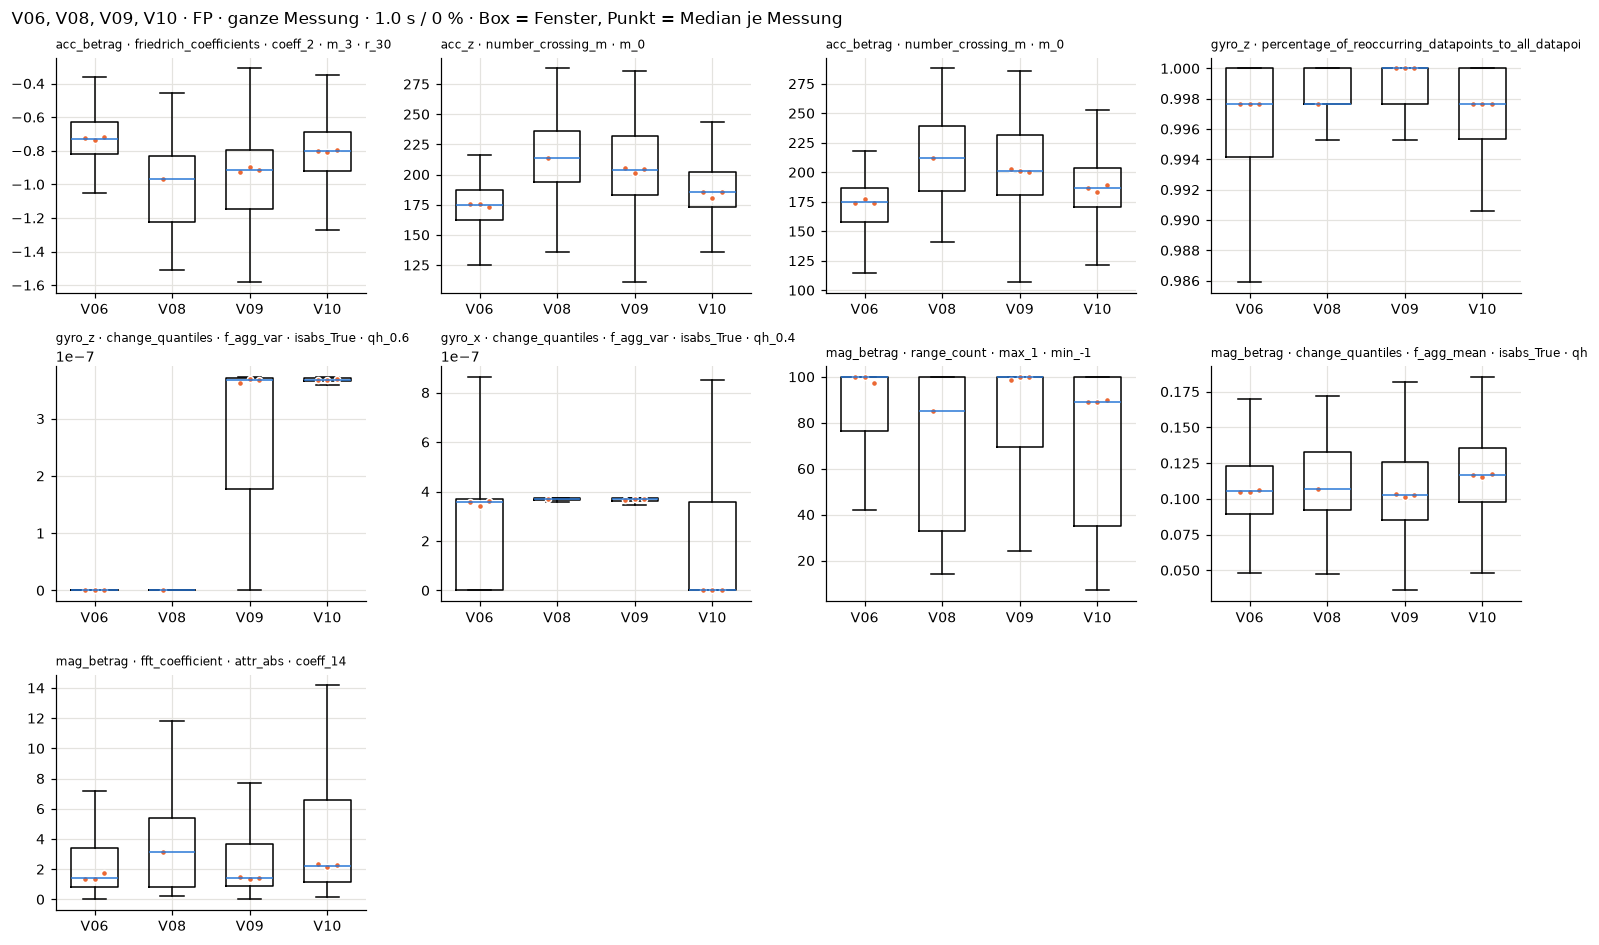

Einteilungen in aufeinanderfolgende Zustände (beste zuerst):


,Einteilung,Blöcke,Trennung (CH)
0,"V06 | V08, V09, V10",2,36.9
1,"V06 | V08, V09 | V10",3,30.0
2,"V06 | V08 | V09, V10",3,22.6
3,"V06, V08 | V09, V10",2,22.5
4,"V06, V08 | V09 | V10",3,21.2
5,"V06, V08, V09 | V10",2,12.8


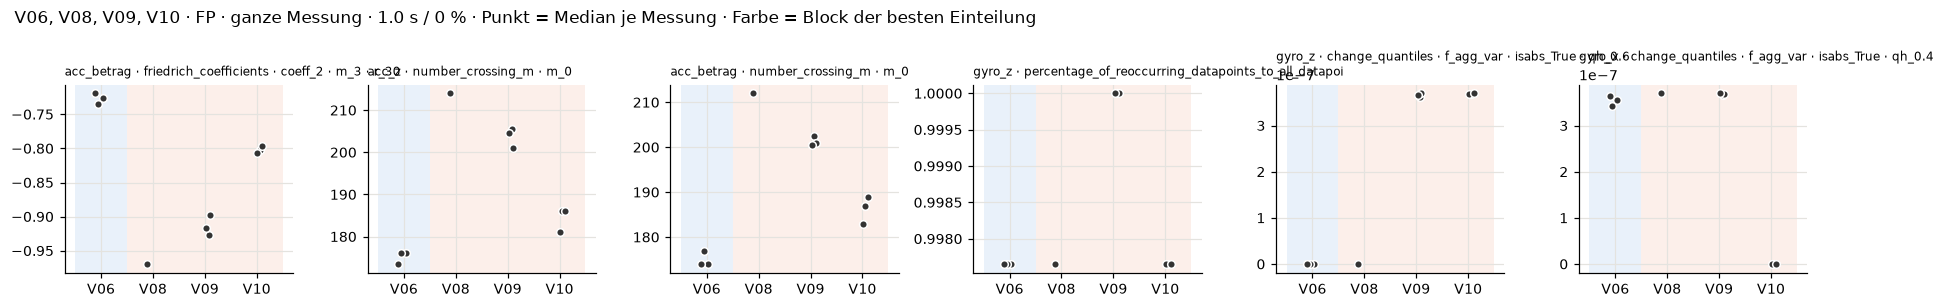

Beste Einteilung (Abstand zur zweitbesten: 1.23×):
    Block 1: V06
    Block 2: V08, V09, V10


In [59]:
RESULT = run(DEFAULT, save_prefix='02_F1')

### 6b · Gruppe B, ausgerichtet, Hin- und Rückfahrt, 2 s (Abb. F0, F3)

Die Messungen werden nach dem Magnetfeld ausgerichtet (Kontrollplot unten: nach der Verschiebung liegen alle |B|-Kurven übereinander). In der ausgerichteten Zeit liegt die **Hinfahrt bei ≈ 3–17 s** und die **Rückfahrt bei ≈ 30–44 s**. Dazwischen steht der Schlitten am Ende der Strecke, in V09 deutlich länger. Diese beiden Bereiche sind nach Sicht auf die Graphen gewählt und gelten für alle Messungen gleich.

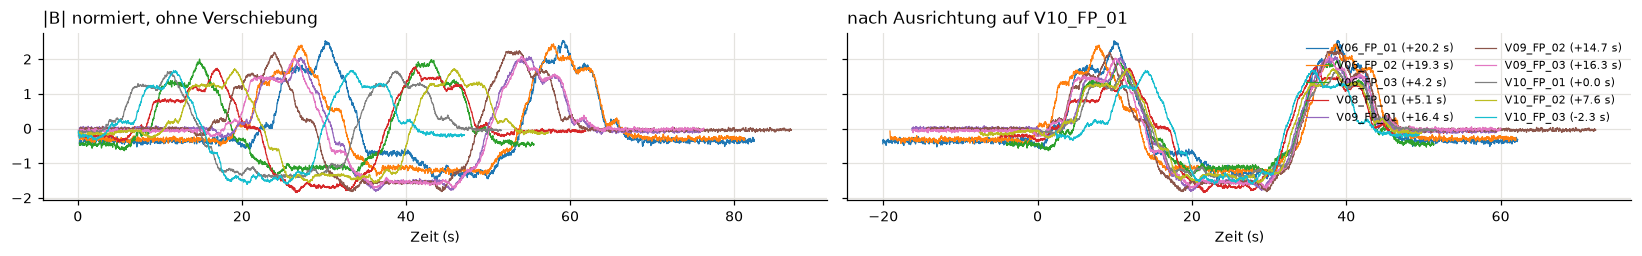

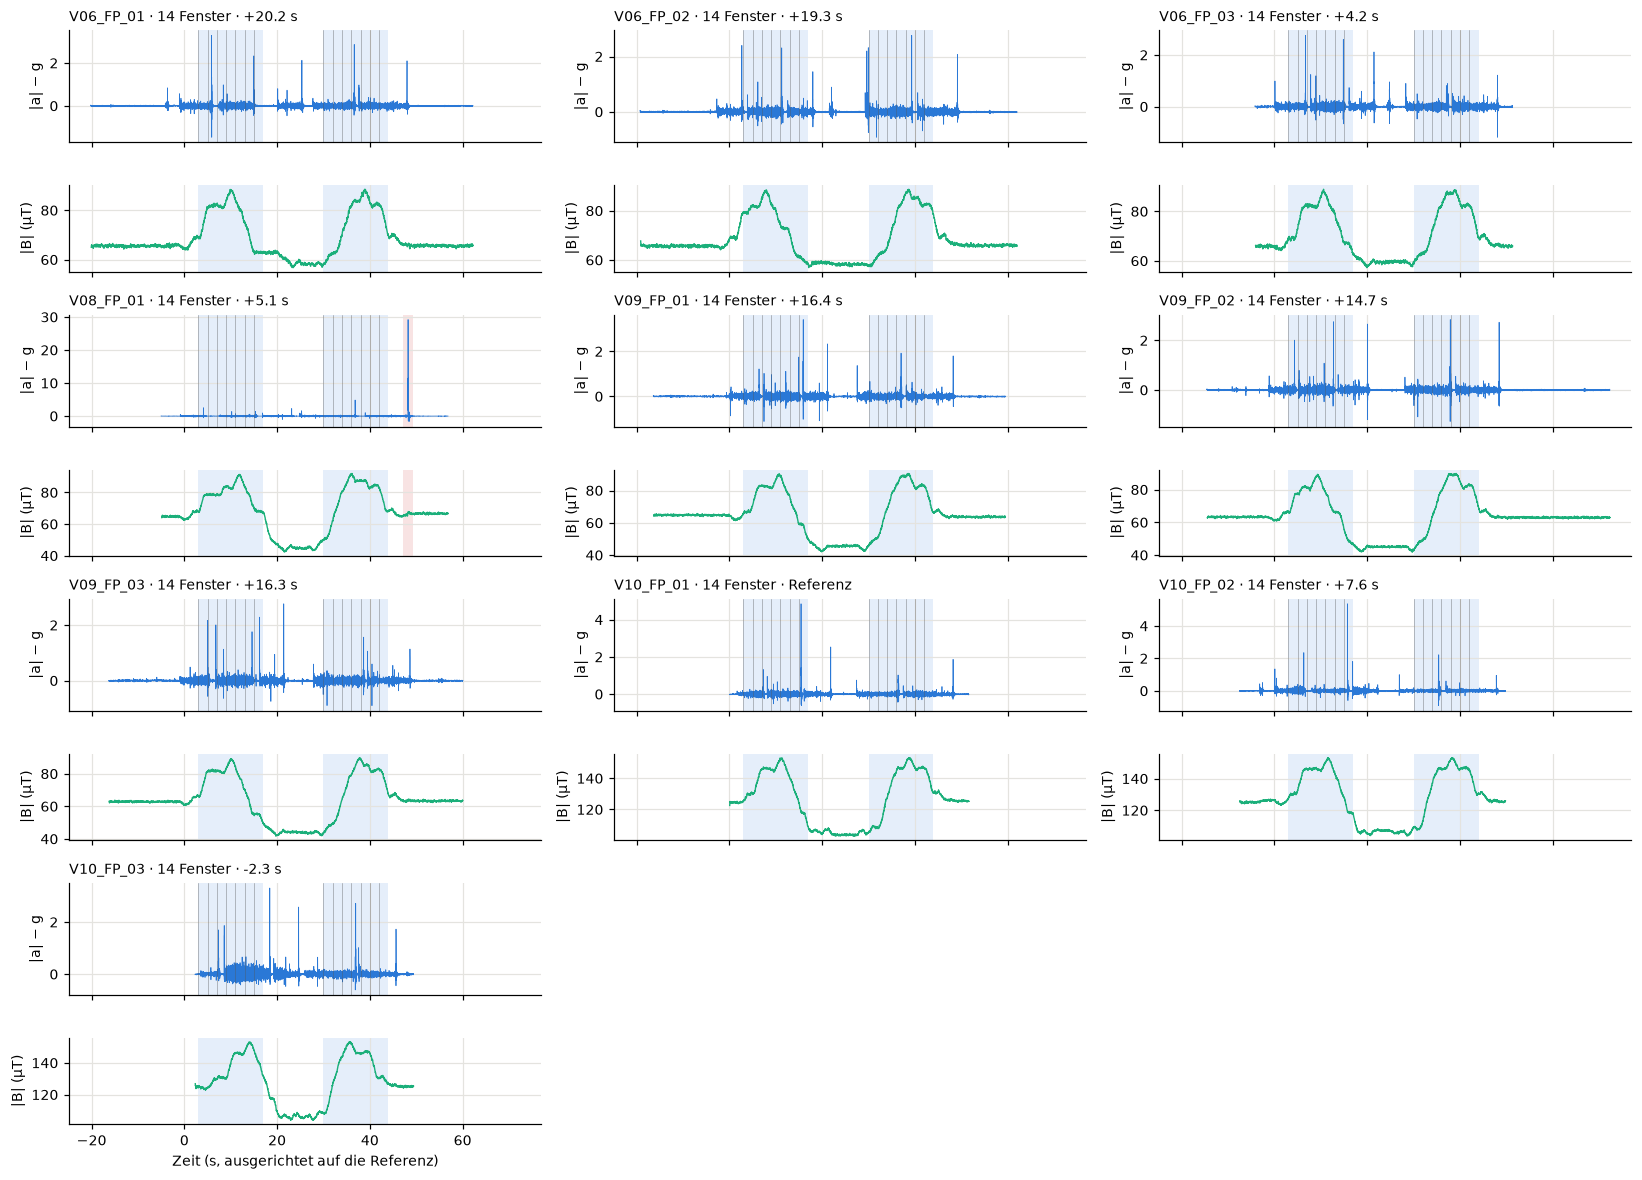

140 Fenster (0 verworfen: Pause, ungültig oder unvollständig) · Features: {'Features roh': 9327, 'nach NaN-Regel': 9269, 'nach Streuungs-Regel': 8670, 'nach Quasi-konstant-Regel': 8491} → 8491 · Rechenzeit 17 s
Fenster je Versuch: {'V06': 42, 'V08': 14, 'V09': 42, 'V10': 42}


,Feature,F,p
acc_x__quantile__q_0.1,acc_x · quantile · q_0.1,488.0026,0.0000
"acc_x__change_quantiles__f_agg_""mean""__isabs_True__qh_0.8__ql_0.2",acc_x · change_quantiles · f_agg_mean · isabs_True · qh_0.8,478.5960,0.0000
"acc_x__change_quantiles__f_agg_""var""__isabs_False__qh_1.0__ql_0.0",acc_x · change_quantiles · f_agg_var · isabs_False · qh_1.0,331.6387,0.0000
"gyro_z__change_quantiles__f_agg_""var""__isabs_False__qh_1.0__ql_0.2",gyro_z · change_quantiles · f_agg_var · isabs_False · qh_1.0,5323.5290,0.0000
"gyro_z__change_quantiles__f_agg_""var""__isabs_False__qh_1.0__ql_0.8",gyro_z · change_quantiles · f_agg_var · isabs_False · qh_1.0,2884.6929,0.0000
gyro_y__quantile__q_0.7,gyro_y · quantile · q_0.7,2651.8289,0.0000
"mag_y__fft_coefficient__attr_""abs""__coeff_71",mag_y · fft_coefficient · attr_abs · coeff_71,32.1853,0.0004
"mag_y__fft_coefficient__attr_""angle""__coeff_69",mag_y · fft_coefficient · attr_angle · coeff_69,23.6904,0.0010
mag_betrag__benford_correlation,mag_betrag · benford_correlation,22.9542,0.0011


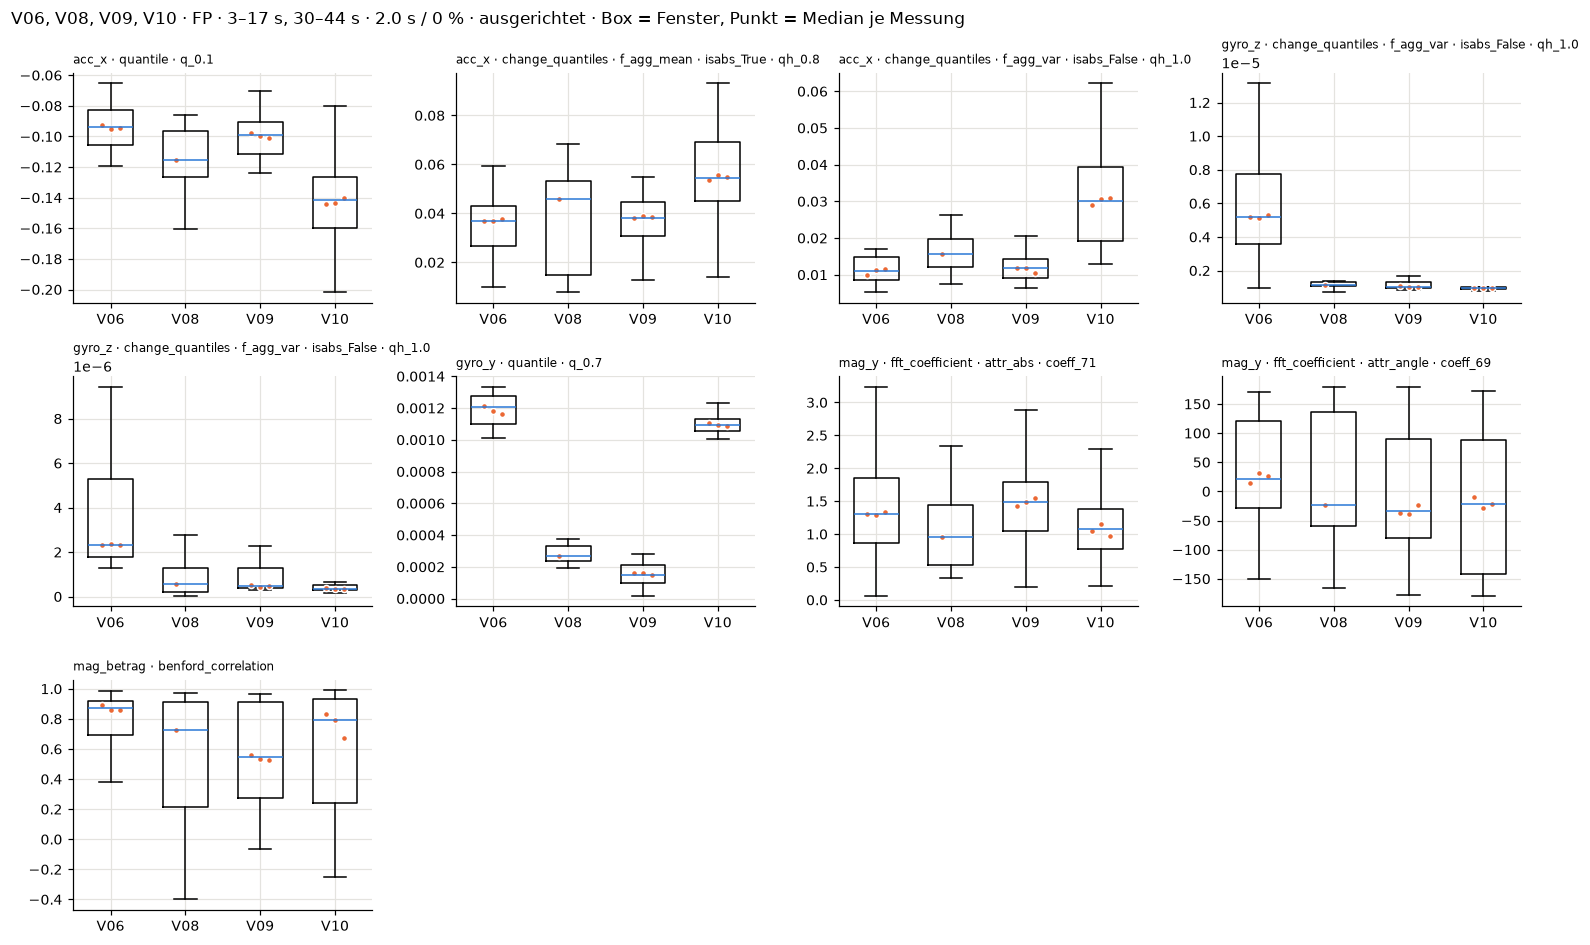

Einteilungen in aufeinanderfolgende Zustände (beste zuerst):


,Einteilung,Blöcke,Trennung (CH)
0,"V06 | V08, V09, V10",2,19.4
1,"V06 | V08, V09 | V10",3,19.2
2,"V06, V08, V09 | V10",2,15.5
3,"V06, V08 | V09 | V10",3,14.8
4,"V06, V08 | V09, V10",2,12.9
5,"V06 | V08 | V09, V10",3,10.2


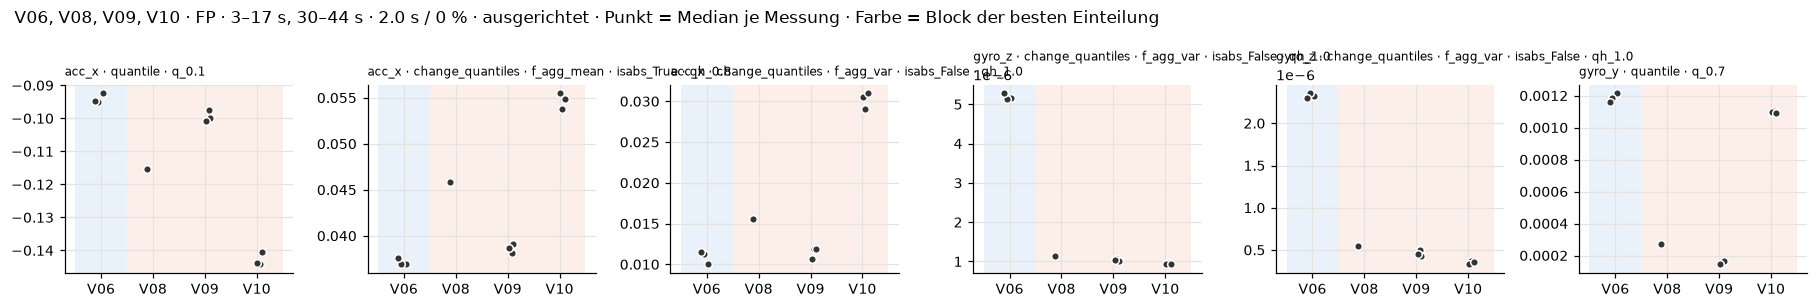

Beste Einteilung (Abstand zur zweitbesten: 1.01×):
    Block 1: V06
    Block 2: V08, V09, V10


In [60]:
B = dict(DEFAULT, ausrichten=True, bereiche=[(3, 17), (30, 44)], laenge=2.0)
fig = plot_alignment(B); fig.savefig(FIG / '02_F0a_ausrichtung.png', dpi=120); plt.show()
fig = plot_selection(B); fig.savefig(FIG / '02_F0_bereich.png', dpi=120); plt.show()
RESULT_B = run(B, save_prefix='02_F3')

### 6c · Basis prüfen: Fairphone ortsfest, V01–V05 (Abb. F4)

**V01 war im Basiszustand.** In V01–V05 lag das Fairphone immer ortsfest am Gestell, der Aufbau ist also vergleichbar. Frage: Sehen V02–V05 noch wie V01 aus? V01 hat nur eine Messung, deshalb kommt die Streuung innerhalb der Versuche aus V03–V05. Ganze Messung, 2 s. V03_FP_02 ist ab 27 s ungültig (Handy verschoben) und fließt nur bis dahin ein.

Zuerst mit allen Achsen:

229 Fenster (13 verworfen: Pause, ungültig oder unvollständig) · Features: {'Features roh': 9327, 'nach NaN-Regel': 9265, 'nach Streuungs-Regel': 8695, 'nach Quasi-konstant-Regel': 8471} → 8471 · Rechenzeit 28 s
Fenster je Versuch: {'V01': 21, 'V02': 25, 'V03': 61, 'V04': 46, 'V05': 76}


,Feature,F,p
"acc_x__change_quantiles__f_agg_""var""__isabs_True__qh_0.2__ql_0.0",acc_x · change_quantiles · f_agg_var · isabs_True · qh_0.2 ·,4.751969e+02,0.0000
"acc_x__change_quantiles__f_agg_""var""__isabs_True__qh_1.0__ql_0.0",acc_x · change_quantiles · f_agg_var · isabs_True · qh_1.0 ·,4.723518e+02,0.0000
"acc_x__change_quantiles__f_agg_""var""__isabs_True__qh_1.0__ql_0.2",acc_x · change_quantiles · f_agg_var · isabs_True · qh_1.0 ·,4.059464e+02,0.0000
"gyro_z__augmented_dickey_fuller__attr_""pvalue""__autolag_""AIC""",gyro_z · augmented_dickey_fuller · attr_pvalue · autolag_AIC,8.870577e+15,0.0000
gyro_z__mean_second_derivative_central,gyro_z · mean_second_derivative_central,1.365790e+15,0.0000
"gyro_z__agg_autocorrelation__f_agg_""var""__maxlag_40",gyro_z · agg_autocorrelation · f_agg_var · maxlag_40,2.695908e+04,0.0000
"mag_z__change_quantiles__f_agg_""mean""__isabs_True__qh_0.8__ql_0.0",mag_z · change_quantiles · f_agg_mean · isabs_True · qh_0.8,4.705110e+01,0.0004
mag_z__mean_abs_change,mag_z · mean_abs_change,4.648460e+01,0.0004
"mag_x__change_quantiles__f_agg_""var""__isabs_False__qh_1.0__ql_0.0",mag_x · change_quantiles · f_agg_var · isabs_False · qh_1.0,4.113180e+01,0.0005


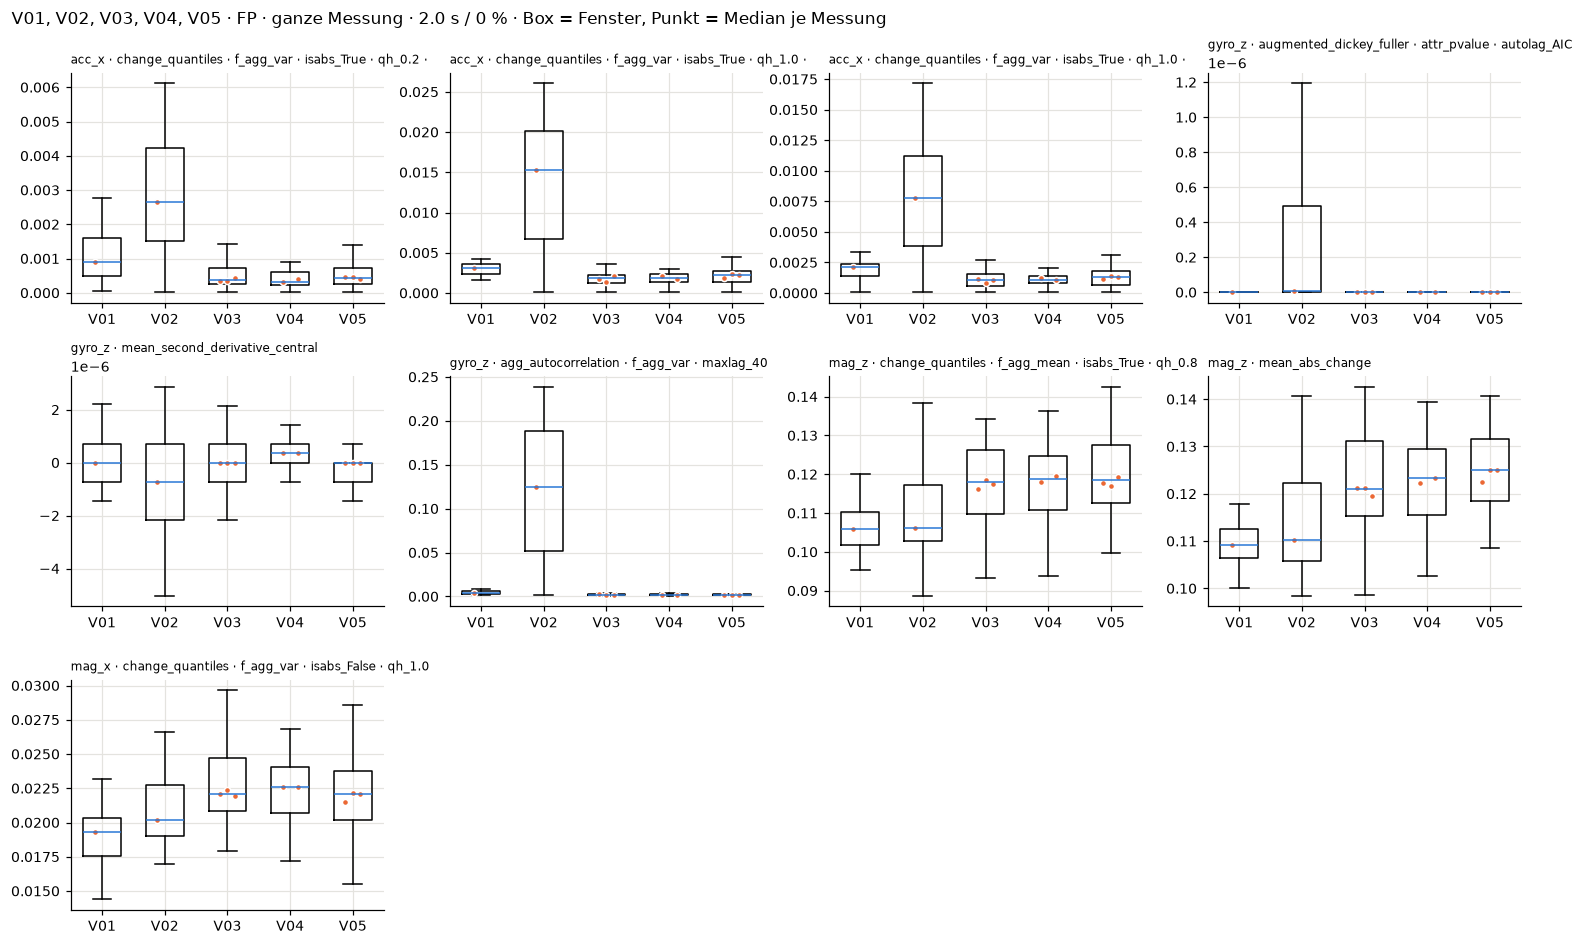

Einteilungen in aufeinanderfolgende Zustände (beste zuerst):


,Einteilung,Blöcke,Trennung (CH)
0,"V01, V02 | V03, V04, V05",2,70.5
1,"V01 | V02 | V03, V04, V05",3,58.6
2,"V01, V02 | V03, V04 | V05",3,35.6
3,"V01, V02 | V03 | V04, V05",3,35.3
4,"V01, V02, V03 | V04, V05",2,15.8
5,"V01 | V02, V03 | V04, V05",3,9.2
6,"V01, V02, V03 | V04 | V05",3,8.1
7,"V01, V02, V03, V04 | V05",2,7.7


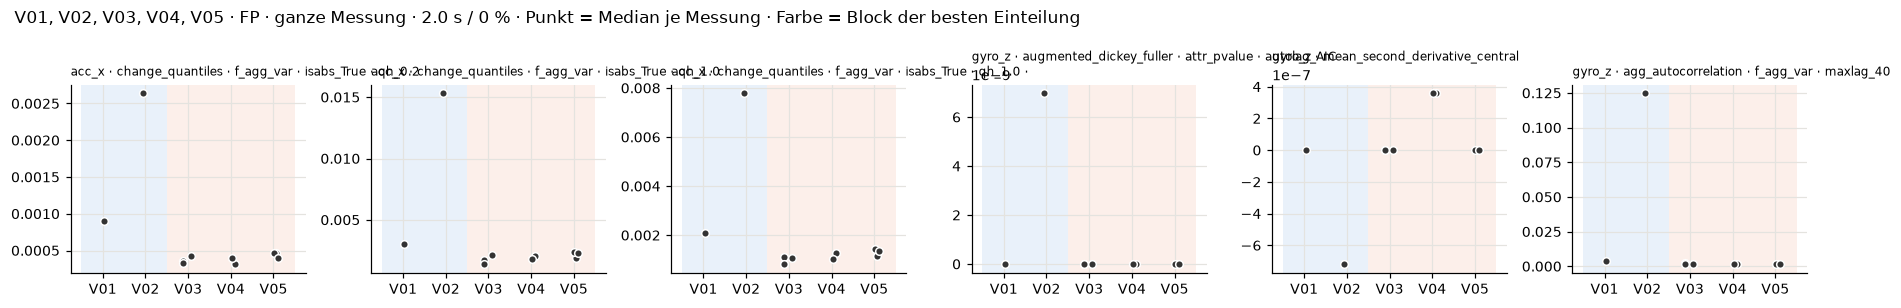

Beste Einteilung (Abstand zur zweitbesten: 1.20×):
    Block 1: V01, V02
    Block 2: V03, V04, V05


In [61]:
A = dict(DEFAULT, versuche=['V01', 'V02', 'V03', 'V04', 'V05'], laenge=2.0)
RESULT_A = run(A, save_prefix='02_F4')

Dann **nur mit den Beträgen** (|a|, |B|), also unabhängig davon, wie das Handy ausgerichtet war (Abb. F5):

229 Fenster (13 verworfen: Pause, ungültig oder unvollständig) · Features: {'Features roh': 2334, 'nach NaN-Regel': 2326, 'nach Streuungs-Regel': 2182, 'nach Quasi-konstant-Regel': 2128} → 2128 · Rechenzeit 8 s
Fenster je Versuch: {'V01': 21, 'V02': 25, 'V03': 61, 'V04': 46, 'V05': 76}


,Feature,F,p
"acc_betrag__agg_linear_trend__attr_""slope""__chunk_len_10__f_agg_""var""",acc_betrag · agg_linear_trend · attr_slope · chunk_len_10 ·,68.8496,0.0001
acc_betrag__partial_autocorrelation__lag_4,acc_betrag · partial_autocorrelation · lag_4,43.8097,0.0004
"acc_betrag__change_quantiles__f_agg_""mean""__isabs_True__qh_0.6__ql_0.4",acc_betrag · change_quantiles · f_agg_mean · isabs_True · qh,36.1067,0.0007
"gyro_betrag__augmented_dickey_fuller__attr_""pvalue""__autolag_""AIC""",gyro_betrag · augmented_dickey_fuller · attr_pvalue · autola,117.2198,0.0000
"gyro_betrag__fft_coefficient__attr_""real""__coeff_14",gyro_betrag · fft_coefficient · attr_real · coeff_14,39.2519,0.0006
"gyro_betrag__fft_coefficient__attr_""abs""__coeff_14",gyro_betrag · fft_coefficient · attr_abs · coeff_14,34.7733,0.0008
"mag_betrag__change_quantiles__f_agg_""mean""__isabs_True__qh_0.6__ql_0.0",mag_betrag · change_quantiles · f_agg_mean · isabs_True · qh,21.3665,0.0024
"mag_betrag__fft_coefficient__attr_""real""__coeff_51",mag_betrag · fft_coefficient · attr_real · coeff_51,18.8782,0.0032
"mag_betrag__fft_coefficient__attr_""imag""__coeff_94",mag_betrag · fft_coefficient · attr_imag · coeff_94,17.6642,0.0037


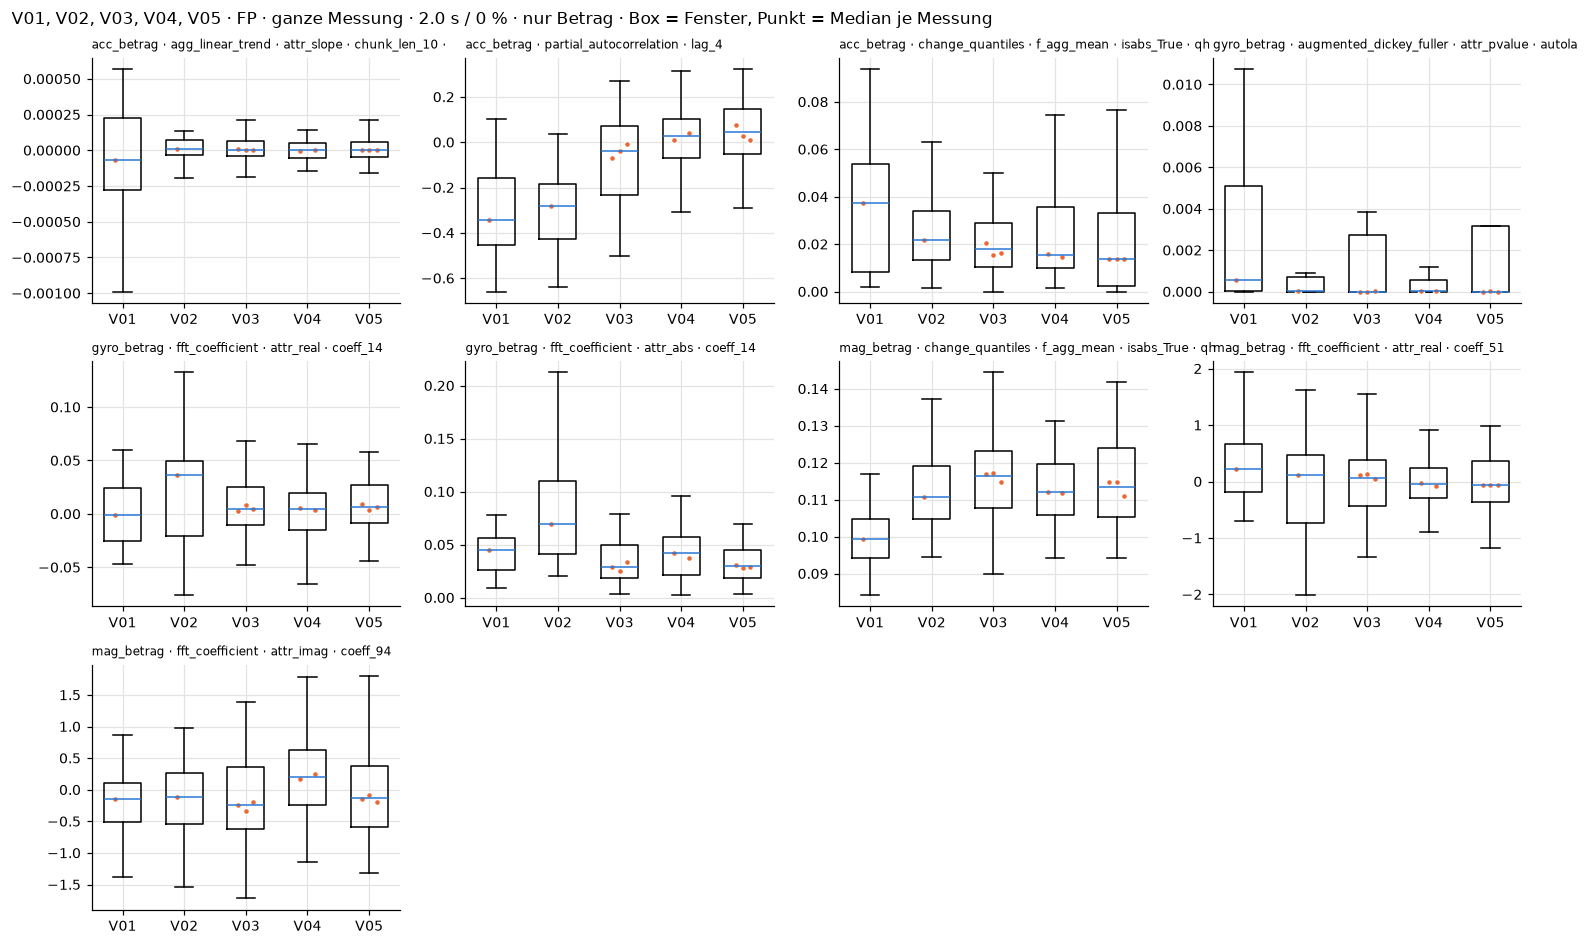

Einteilungen in aufeinanderfolgende Zustände (beste zuerst):


,Einteilung,Blöcke,Trennung (CH)
0,"V01, V02 | V03, V04, V05",2,4.7
1,"V01 | V02 | V03, V04, V05",3,3.4
2,"V01 | V02, V03, V04, V05",2,3.2
3,"V01, V02 | V03, V04 | V05",3,2.7
4,"V01, V02 | V03 | V04, V05",3,2.6
5,"V01 | V02, V03 | V04, V05",3,2.3
6,"V01 | V02, V03, V04 | V05",3,2.3
7,"V01, V02, V03 | V04, V05",2,2.2


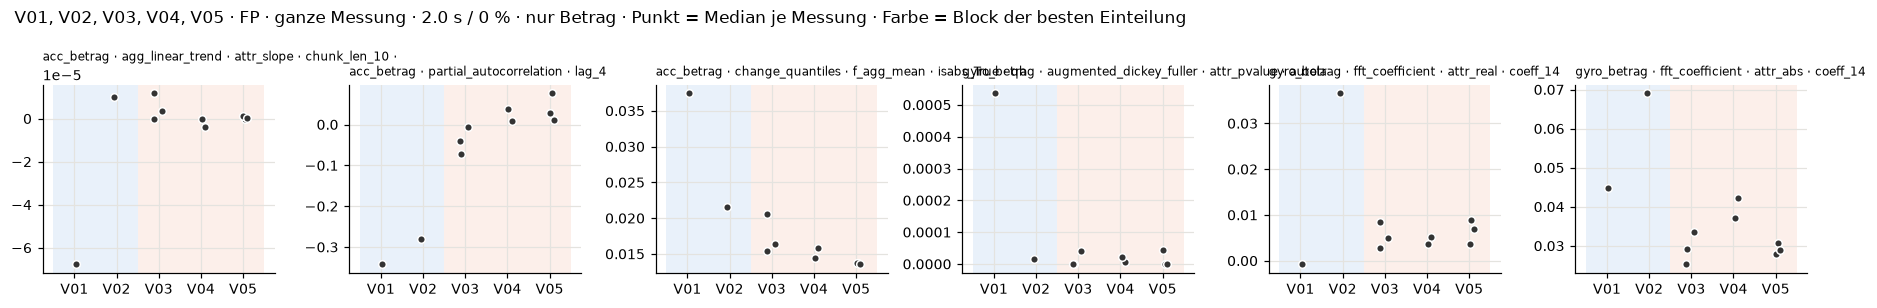

Beste Einteilung (Abstand zur zweitbesten: 1.40×):
    Block 1: V01, V02
    Block 2: V03, V04, V05


In [62]:
A_BETRAG = dict(A, nur_betrag=True)
RESULT_A_BETRAG = run(A_BETRAG, save_prefix='02_F5')

### 6d · Brücke morgens ↔ nachmittags: iPhone ortsfest (V02, V03, V08, V10)

Das ist der einzige Aufbau, der morgens (V02, V03) und nachmittags (V08, V10) gleich ist: Das iPhone lag ortsfest. Nur Beträge, ganze Messung, 2 s. Unterscheiden sich die Versuche hier, wäre das ein direkter Hinweis auf einen anderen Zustand als die Basis.

152 Fenster (5 verworfen: Pause, ungültig oder unvollständig) · Features: {'Features roh': 2332, 'nach NaN-Regel': 2329, 'nach Streuungs-Regel': 2164, 'nach Quasi-konstant-Regel': 2126} → 2126 · Rechenzeit 8 s
Fenster je Versuch: {'V02': 27, 'V03': 70, 'V08': 29, 'V10': 26}


,Feature,F,p
acc_betrag__fourier_entropy__bins_2,acc_betrag · fourier_entropy · bins_2,9057.3965,0.0001
"acc_betrag__change_quantiles__f_agg_""var""__isabs_True__qh_0.6__ql_0.0",acc_betrag · change_quantiles · f_agg_var · isabs_True · qh_,2621.2319,0.0004
"acc_betrag__change_quantiles__f_agg_""mean""__isabs_True__qh_0.6__ql_0.0",acc_betrag · change_quantiles · f_agg_mean · isabs_True · qh,1436.4651,0.0007
gyro_betrag__ratio_beyond_r_sigma__r_2.5,gyro_betrag · ratio_beyond_r_sigma · r_2.5,14684.3148,0.0001
"gyro_betrag__fft_coefficient__attr_""abs""__coeff_57",gyro_betrag · fft_coefficient · attr_abs · coeff_57,710.0797,0.0014
"gyro_betrag__fft_coefficient__attr_""imag""__coeff_45",gyro_betrag · fft_coefficient · attr_imag · coeff_45,489.5846,0.0020
"mag_betrag__fft_coefficient__attr_""imag""__coeff_83",mag_betrag · fft_coefficient · attr_imag · coeff_83,3022.6779,0.0003
mag_betrag__ratio_beyond_r_sigma__r_2,mag_betrag · ratio_beyond_r_sigma · r_2,1968.8333,0.0005
"mag_betrag__fft_coefficient__attr_""imag""__coeff_61",mag_betrag · fft_coefficient · attr_imag · coeff_61,632.5819,0.0016


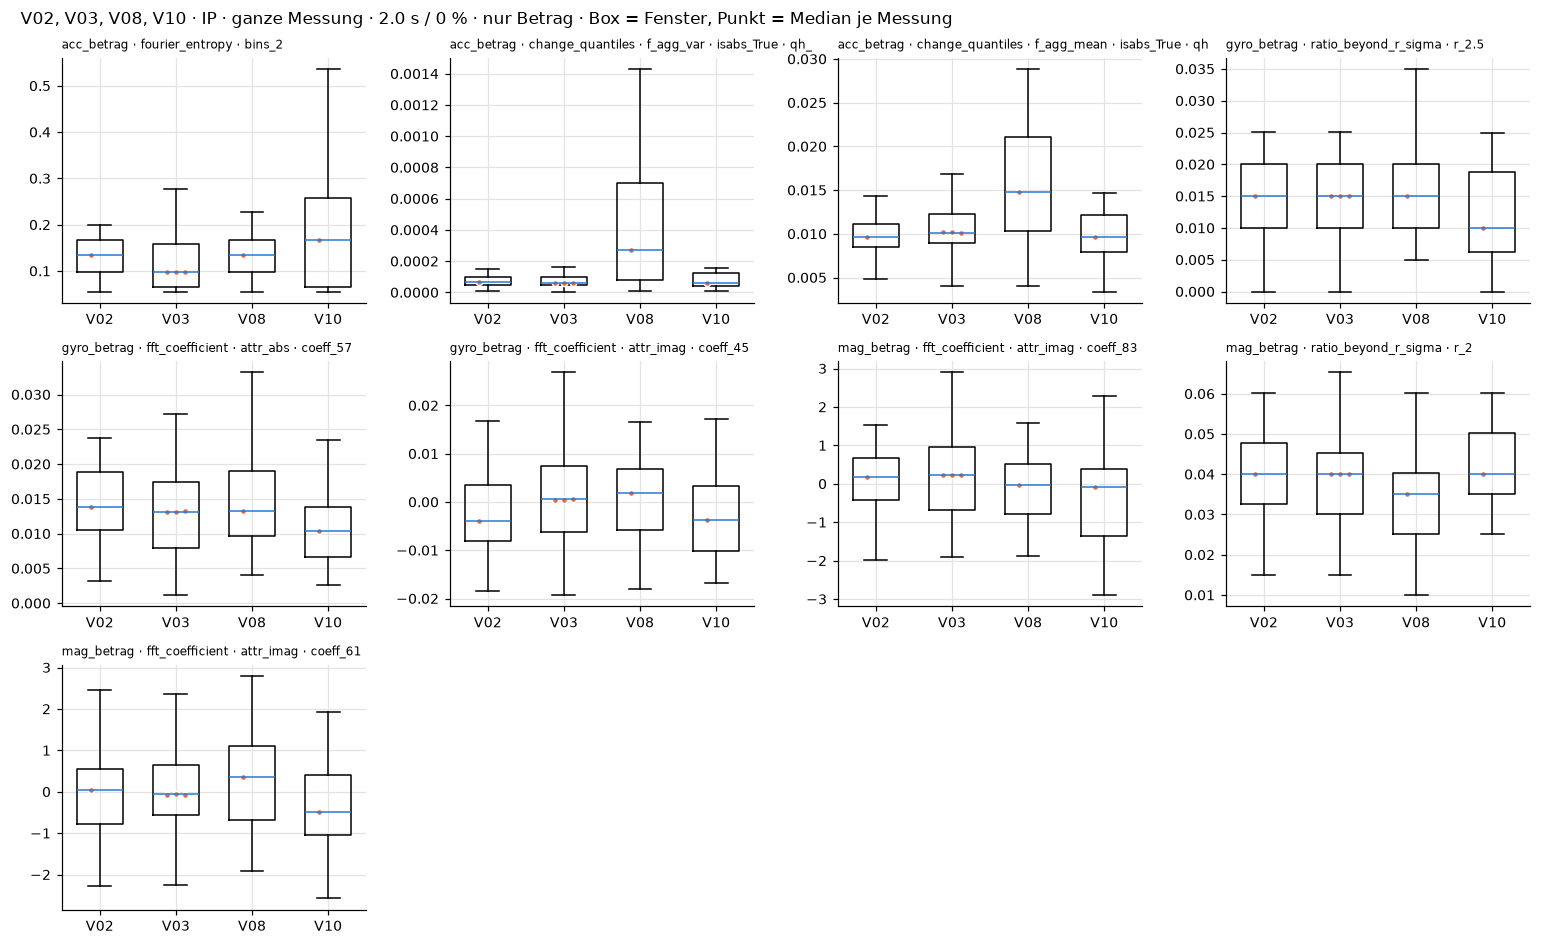

Einteilungen in aufeinanderfolgende Zustände (beste zuerst):


,Einteilung,Blöcke,Trennung (CH)
0,"V02, V03 | V08 | V10",3,7.6
1,"V02, V03 | V08, V10",2,5.9
2,"V02 | V03 | V08, V10",3,3.2
3,"V02, V03, V08 | V10",2,2.8
4,"V02 | V03, V08 | V10",3,2.0
5,"V02 | V03, V08, V10",2,1.0


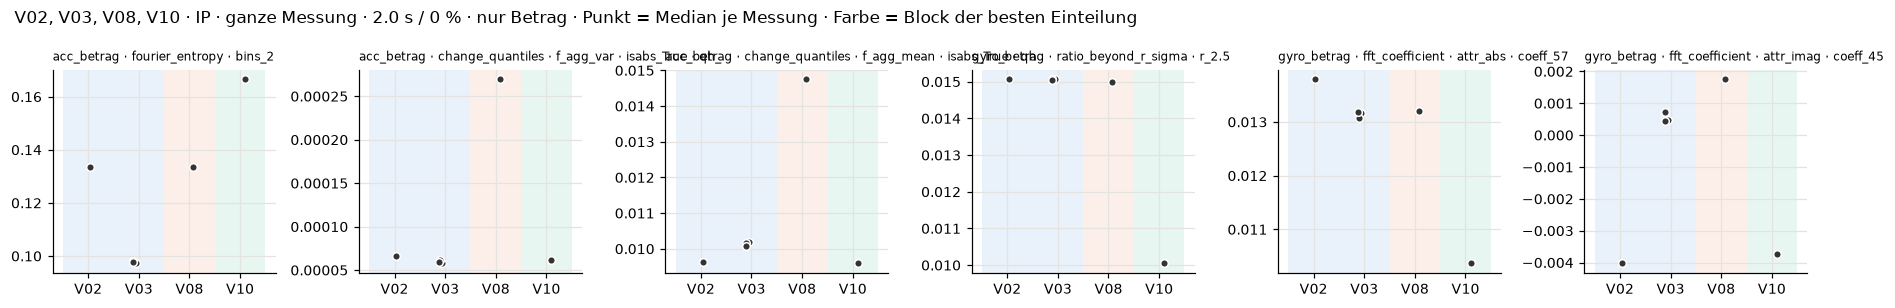

Beste Einteilung (Abstand zur zweitbesten: 1.29×):
    Block 1: V02, V03
    Block 2: V08
    Block 3: V10


In [63]:
BRUECKE = dict(DEFAULT, versuche=['V02', 'V03', 'V08', 'V10'], geraet='IP', laenge=2.0, nur_betrag=True)
RESULT_BRUECKE = run(BRUECKE, save_prefix='02_F6')

### 6e · iPhone auf dem Schlitten (V04, V05)

Die vierte vergleichbare Gruppe: Das iPhone fuhr in V04 und V05 auf dem Schlitten mit (morgens). Nur zwei Versuche, also nur eine mögliche Einteilung (V04 | V05). Ihr CH zeigt, wie stark sich zwei Versuche **im selben Zustand** unterscheiden: ein Vergleichswert für die anderen Gruppen. Ausgerichtet, ganze Messung, 2 s.

144 Fenster (0 verworfen: Pause, ungültig oder unvollständig) · Features: {'Features roh': 9325, 'nach NaN-Regel': 9310, 'nach Streuungs-Regel': 8673, 'nach Quasi-konstant-Regel': 8511} → 8511 · Rechenzeit 14 s
Fenster je Versuch: {'V04': 71, 'V05': 73}


,Feature,F,p
"acc_z__fft_coefficient__attr_""abs""__coeff_38",acc_z · fft_coefficient · attr_abs · coeff_38,171.2398,0.0002
acc_y__minimum,acc_y · minimum,115.0117,0.0004
"acc_betrag__fft_coefficient__attr_""abs""__coeff_61",acc_betrag · fft_coefficient · attr_abs · coeff_61,58.1011,0.0016
"gyro_y__fft_coefficient__attr_""abs""__coeff_32",gyro_y · fft_coefficient · attr_abs · coeff_32,270.9288,0.0001
"gyro_x__change_quantiles__f_agg_""var""__isabs_False__qh_0.2__ql_0.0",gyro_x · change_quantiles · f_agg_var · isabs_False · qh_0.2,157.7118,0.0002
"gyro_z__fft_coefficient__attr_""abs""__coeff_26",gyro_z · fft_coefficient · attr_abs · coeff_26,143.9641,0.0003
mag_betrag__energy_ratio_by_chunks__num_segments_10__segment_focus_4,mag_betrag · energy_ratio_by_chunks · num_segments_10 · segm,144.7786,0.0003
mag_betrag__number_crossing_m__m_1,mag_betrag · number_crossing_m · m_1,121.0000,0.0004
"mag_x__fft_coefficient__attr_""angle""__coeff_23",mag_x · fft_coefficient · attr_angle · coeff_23,87.5289,0.0007


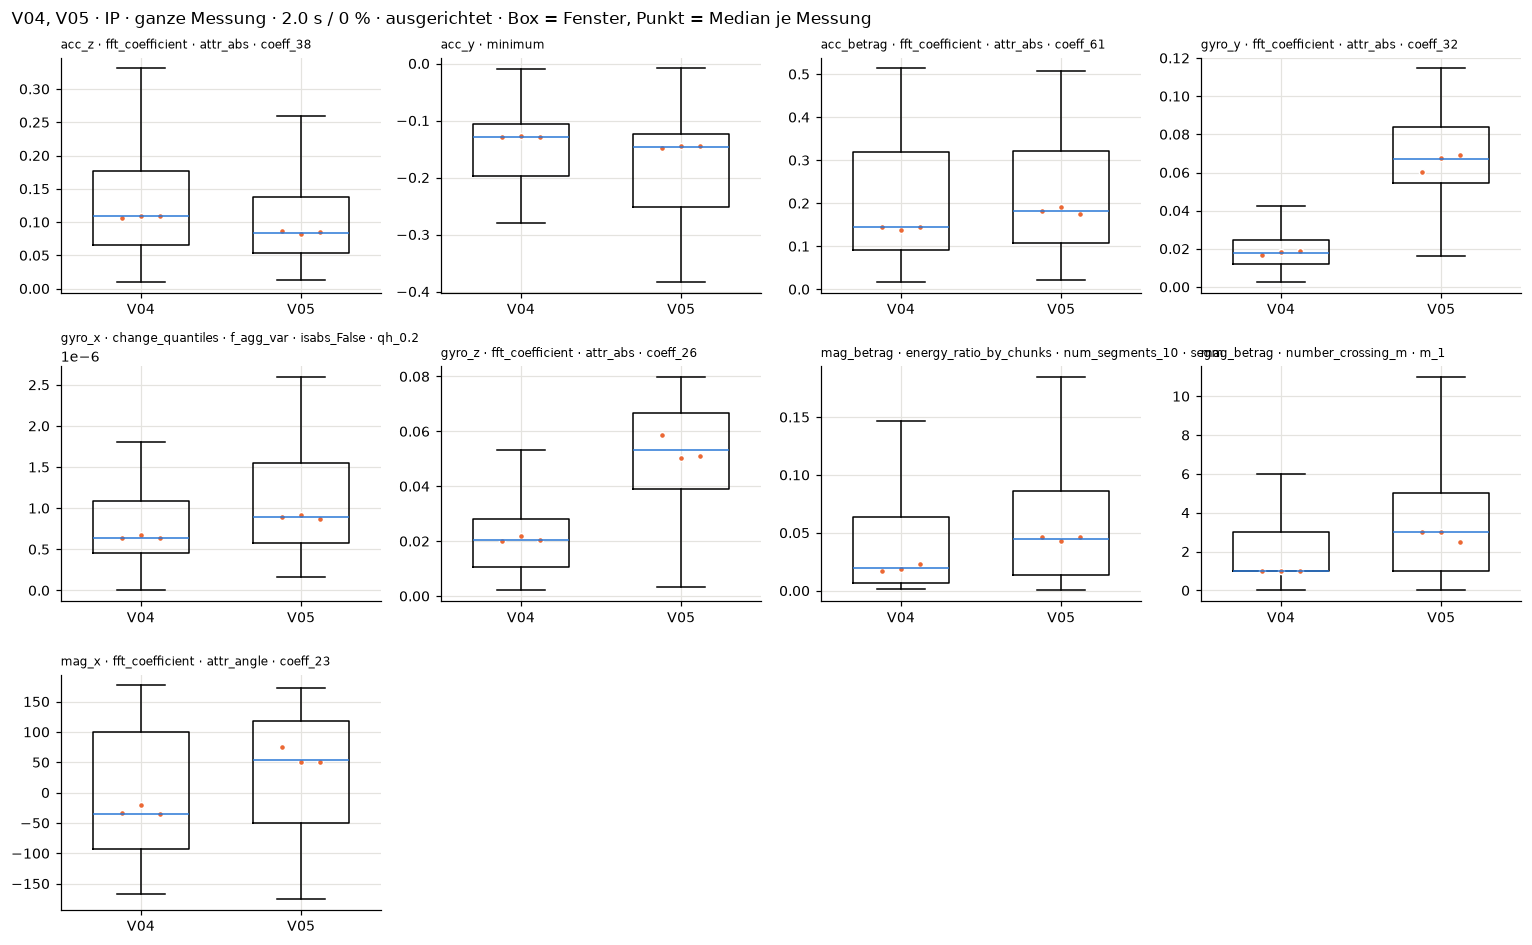

Einteilungen in aufeinanderfolgende Zustände (beste zuerst):


,Einteilung,Blöcke,Trennung (CH)
0,V04 | V05,2,7.0


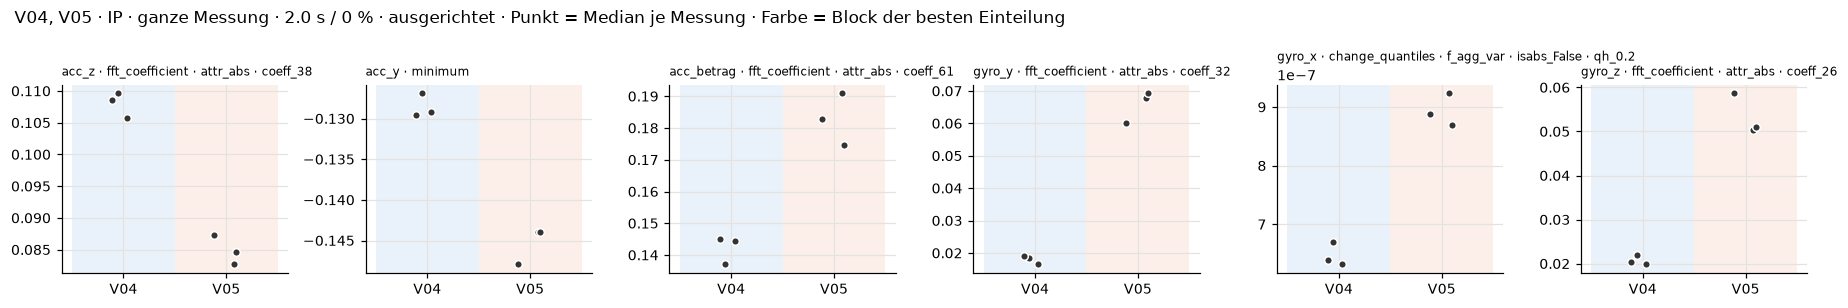

Beste Einteilung (Abstand zur zweitbesten: nan×):
    Block 1: V04
    Block 2: V05


In [64]:
IP_SCHLITTEN = dict(DEFAULT, versuche=['V04', 'V05'], geraet='IP', laenge=2.0, ausrichten=True)
RESULT_IP = run(IP_SCHLITTEN, save_prefix='02_F7')

## 7 · Fensterlängen vergleichen

Dieselbe Auswahl wie in 6b mit verschiedenen Fensterlängen ohne Überlappung. Kennzahlen: **F der Top-5** (wie klar die Features die Versuche trennen), die **beste Einteilung** und ihr **Abstand** zur zweitbesten. Bleibt die beste Einteilung über die Längen gleich, ist sie robust. Zusätzlich wird gezählt, wie oft jede Einteilung unter den **besten zwei** landet: Eine Einteilung, die bei jeder Länge oben steht, ist belastbarer als eine, die nur bei einer Länge gewinnt. **Abb. F2.** Für andere Versuche oder Bereiche `cfg` in der Zelle anpassen.

Wie oft steht eine Einteilung über alle Längen unter den besten zwei?


,von 5 Längen
"V06 | V08, V09 | V10",4
"V06 | V08, V09, V10",3
"V06, V08, V09 | V10",2
"V06 | V08 | V09, V10",1


,Länge (s),Fenster,F Top-5 (Median),Beste Einteilung,CH,Zweitbeste,Abstand
0,0.5,560,399.50,"V06, V08, V09 | V10",36.35,"V06 | V08, V09 | V10",1.24
1,1.0,280,621.26,"V06 | V08, V09, V10",14.38,"V06 | V08 | V09, V10",1.03
2,2.0,140,488.00,"V06 | V08, V09, V10",19.41,"V06 | V08, V09 | V10",1.01
3,3.0,80,200.44,"V06 | V08, V09, V10",37.64,"V06 | V08, V09 | V10",1.19
4,5.0,40,439.07,"V06, V08, V09 | V10",9.53,"V06 | V08, V09 | V10",1.26


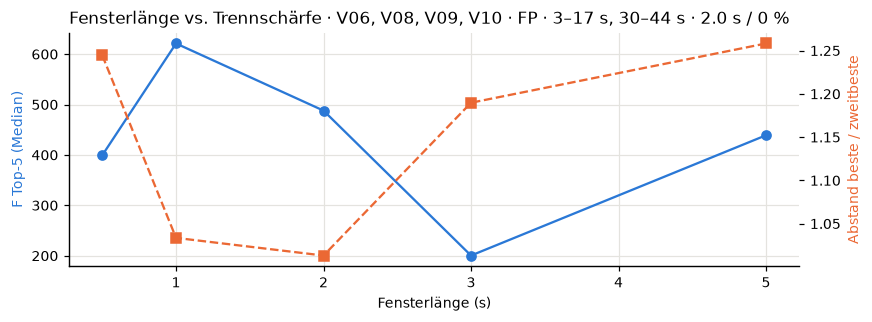

In [65]:
def compare_lengths(base, lengths=(0.5, 1, 2, 3, 5)):
    rows = []
    for L in lengths:
        r = run(dict(base, laenge=L, ueberlappung=0), show=False)
        seg = r['einteilungen']
        rows.append({'Länge (s)': L, 'Fenster': len(r['meta']), 'F Top-5 (Median)': r['ranking'].loc[r['top'][:5], 'F'].median(),
                     'Beste Einteilung': seg.iloc[0]['Einteilung'], 'CH': seg.iloc[0]['Trennung (CH)'],
                     'Zweitbeste': seg.iloc[1]['Einteilung'], 'Abstand': r['abstand']})
    return pd.DataFrame(rows)

cfg = dict(B)
lengths = compare_lengths(cfg)
top2 = pd.concat([lengths['Beste Einteilung'], lengths['Zweitbeste']]).value_counts()
print('Wie oft steht eine Einteilung über alle Längen unter den besten zwei?')
display(top2.rename(f'von {len(lengths)} Längen').to_frame())
fig, ax1 = plt.subplots(figsize=(8, 3))
ax1.plot(lengths['Länge (s)'], lengths['F Top-5 (Median)'], 'o-', color='#2a78d6')
ax1.set_xlabel('Fensterlänge (s)'); ax1.set_ylabel('F Top-5 (Median)', color='#2a78d6')
ax2 = ax1.twinx(); ax2.plot(lengths['Länge (s)'], lengths['Abstand'], 's--', color='#eb6834')
ax2.set_ylabel('Abstand beste / zweitbeste', color='#eb6834'); ax2.grid(False)
ax1.set_title('Fensterlänge vs. Trennschärfe · ' + describe(cfg).rsplit(' · ', 1)[0], loc='left')
fig.tight_layout(); fig.savefig(FIG / '02_F2_fensterlaenge.png', dpi=150)
lengths.round(2)

## 8 · Protokoll aller Läufe

Jede Berechnung (auch per Button) hängt eine Zeile an `runs_log.csv` an. Neueste zuerst:

In [66]:
pd.read_csv(LOG).iloc[::-1].head(20)

,Zeit,Versuche,Gerät,Sensoren,Bereiche (s),Länge (s),Überlappung (%),Merkmale,Bänder,lageunabhängig,nur Betrag,ausgerichtet,Fenster,Features,F Top-5 (Median),Top-3,Beste Einteilung,CH,Zweitbeste,Abstand,Featurematrix
23,2026-10-30 22:31,V01 V02 V03 V04 V05,FP,acc+gyro+mag,ganz,1.0,25,efficient,True,True,False,False,602,7633,251.9,acc_x · agg_linear_trend · attr_stderr · chunk_len_10 · f_ag | acc_x · chang...,"V01, V02 | V03, V04, V05",201.3,"V01 | V02 | V03, V04, V05",1.05,NaN
22,2026-10-30 22:31,V01 V02 V03 V04 V05,FP,acc+gyro+mag,ganz,1.0,25,efficient,True,True,False,False,602,7633,251.9,acc_x · agg_linear_trend · attr_stderr · chunk_len_10 · f_ag | acc_x · chang...,"V01, V02 | V03, V04, V05",201.3,"V01 | V02 | V03, V04, V05",1.05,NaN
21,2026-10-30 22:30,V06 V08 V09 V10,FP,acc+gyro+mag,"3-17, 30-44",5.0,0,efficient,True,True,False,True,40,8538,439.1,acc_x · change_quantiles · f_agg_mean · isabs_True · qh_1.0 | acc_x · absol...,"V06, V08, V09 | V10",9.5,"V06 | V08, V09 | V10",1.26,NaN
20,2026-10-30 22:30,V06 V08 V09 V10,FP,acc+gyro+mag,"3-17, 30-44",3.0,0,efficient,True,True,False,True,80,8517,200.4,acc_x · quantile · q_0.8 | acc_z · number_crossing_m · m_0 | acc_x · absolut...,"V06 | V08, V09, V10",37.6,"V06 | V08, V09 | V10",1.19,NaN
19,2026-10-30 22:30,V06 V08 V09 V10,FP,acc+gyro+mag,"3-17, 30-44",2.0,0,efficient,True,True,False,True,140,8491,488.0,acc_x · quantile · q_0.1 | acc_x · change_quantiles · f_agg_mean · isabs_Tru...,"V06 | V08, V09, V10",19.4,"V06 | V08, V09 | V10",1.01,NaN
18,2026-10-30 22:30,V06 V08 V09 V10,FP,acc+gyro+mag,"3-17, 30-44",1.0,0,efficient,True,True,False,True,280,7643,621.3,acc_betrag · partial_autocorrelation · lag_7 | acc_x · change_quantiles · f_...,"V06 | V08, V09, V10",14.4,"V06 | V08 | V09, V10",1.03,NaN
17,2026-10-30 22:30,V06 V08 V09 V10,FP,acc+gyro+mag,"3-17, 30-44",0.5,0,efficient,True,True,False,True,560,7195,399.5,acc_z · fft_coefficient · attr_abs · coeff_86 | acc_y · change_quantiles · f...,"V06, V08, V09 | V10",36.3,"V06 | V08, V09 | V10",1.24,NaN
16,2026-10-30 22:30,V04 V05,IP,acc+gyro+mag,ganz,2.0,0,efficient,True,True,False,True,144,8511,157.7,acc_z · fft_coefficient · attr_abs · coeff_38 | acc_y · minimum | acc_betrag...,V04 | V05,7.0,NaN,NaN,NaN
15,2026-10-30 22:29,V02 V03 V08 V10,IP,acc+gyro+mag,ganz,2.0,0,efficient,True,True,True,False,152,2126,2621.2,acc_betrag · fourier_entropy · bins_2 | acc_betrag · change_quantiles · f_ag...,"V02, V03 | V08 | V10",7.6,"V02, V03 | V08, V10",1.29,NaN
14,2026-10-30 22:29,V01 V02 V03 V04 V05,FP,acc+gyro+mag,ganz,2.0,0,efficient,True,True,True,False,229,2128,43.8,acc_betrag · agg_linear_trend · attr_slope · chunk_len_10 · | acc_betrag · ...,"V01, V02 | V03, V04, V05",4.7,"V01 | V02 | V03, V04, V05",1.40,NaN


## Befund

**Bekannt:** V01 war im Basiszustand. Es gibt drei Zustände, und sie kamen **nacheinander**. Gesucht sind zwei Wechselstellen in der Folge V01 → V10. Verwendet werden Beschleunigung, Gyroskop und Magnetfeld, je Sensor die 3 besten Features.

- **Nachmittags, Fairphone auf dem Schlitten (6b, 7):**
  - Ausgerichtet nach Magnetfeld, Hin- und Rückfahrt. Die Ausrichtung funktioniert gut (Abb. F0a).
  - **Beide Sensoren sehen je einen Wechsel:** Die **Beschleunigung** trennt vor allem **V10** ab (V06, V08, V09 | V10). Das **Gyroskop** trennt vor allem **V06** ab (V06 | V08, V09, V10): Die Drehrate um z ist in V06 in allen drei Wiederholungen etwa 2,5× unruhiger.
  - **Robustheit (Abschnitt 7):** Die Einteilung **V06 | V08, V09 | V10** steht bei **4 von 5 Fensterlängen** unter den besten zwei, häufiger als jede andere. Die beste Einteilung allein wechselt je nach Länge zwischen „V06 | Rest“ und „Rest | V10“, mit kleinem Abstand (1,0–1,3×).
  - → **Nachmittags gibt es zwei Wechsel: vor V08 und vor V10.**
- **Morgens, Fairphone ortsfest (6c):** Mit allen Achsen scheinbar V01, V02 | V03–V05, aber getrieben von der Lage des Handys (acc_x). Nur mit Beträgen sehr schwach (CH 4,7). → **Kein Wechsel erkennbar.**
- **Vergleichswert „gleicher Zustand“ (6e):** V04 | V05 (iPhone auf dem Schlitten, beide morgens) erreicht CH 7,0. So stark unterscheiden sich zwei Versuche **ohne** Zustandswechsel.
- **Brücke (6d, iPhone ortsfest):** V02, V03 | V08 | V10 mit CH 7,6, also kaum mehr als der Vergleichswert. → Das ortsfeste iPhone **zeigt keinen belastbaren Unterschied** zwischen morgens und nachmittags.
- **Zuordnung (am besten gestützt):**

  | Basis | Zustand 1 | Zustand 2 |
  |---|---|---|
  | **V01–V06** (V07 *) | **V08, V09** | **V10** |

  - \* V07 hat keine Fahrt und lässt sich nicht messen. Wegen der Reihenfolge gehört V07 entweder noch zur Basis oder schon zu Zustand 1.
  - Diese Einteilung erklärt alle Beobachtungen mit **zwei gemessenen Wechseln** (vor V08, vor V10). Morgens ist kein Wechsel zu sehen, und zwischen V05 und V06 muss keiner angenommen werden. Dort wurde nur das Handy umgesetzt.
- **Grenzen:**
  - Der Wechsel **vor V10** ist am besten belegt (Beschleunigung, alle Wiederholungen, 21 min Pause davor).
  - Der Wechsel **vor V08** beruht vor allem auf dem Gyroskop, das hier an seiner Auflösungsgrenze misst. Außerdem wurde in **V07 das Handy angefasst** (Rucke über 30 m/s²). Ein leicht verändert befestigtes Handy könnte denselben Unterschied erzeugen. Das Versuchsprotokoll sollte das klären.
  - **Alternative:** Basis V01–V05, Zustand 1 V06–V09, Zustand 2 V10. Dann läge ein Wechsel genau am Umbau V05 → V06, den die Daten nicht messen können. V06 würde sich dann aber trotzdem von V08/V09 unterscheiden, was diese Alternative nicht erklärt.
- **Nächste Schritte:** Betreuer fragen, was vor V08 (bzw. in V07) und vor V10 geändert wurde. Für Session 3: Baseline mit Trennung nach Messung (Leave-one-recording-out) mit den Einstellungen aus 6b.